<a href="https://colab.research.google.com/github/rebhimariem27-tech/Intrusion-Detection-Agent-RL/blob/main/Intrusion_Detection_Agent_Visual_Validation_Corrige.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intrusion Detection Agent — Simulation synthétique enrichie

**Projet RL en cybersécurité **

Cette version conserve l'étude de la récompense et de ses pondérations.

### Objectifs
1. enrichir les états en intégrant la criticité de l'actif ;
2. proposer des actions de réponse graduées ;
3. appliquer les contraintes de sécurité indépendamment de la reward ;
4. comparer plusieurs configurations de lambdas avec des métriques externes ;
5. comparer l'apprentissage Q-learning sur plusieurs graines et hyperparamètres.

> **Limite scientifique :** toutes les probabilités, valeurs de risque, coûts, dommages et seuils présentés dans ce notebook sont des hypothèses de scénario. Les résultats décrivent uniquement ce simulateur. Ils ne prouvent pas la performance d'un agent sur un réseau réel et ne constituent pas une calibration opérationnelle.

## 1. Décisions de modélisation

- L'environnement reste entièrement synthétique : aucune interface réseau ni action réelle n'est exécutée.
- Les observations sont des catégories abstraites de risque (`Normal`, `Suspicious`, `HighRisk`, `Isolated`, `VerifiedSafe`), et non des labels terrain validés. Les événements tels que fausse alerte ou fausse isolation sont utilisés uniquement par l'évaluateur du simulateur.
- Chaque état inclut une criticité `Standard` ou `Critical` : l'agent ne doit pas choisir la même réponse pour tous les actifs.
- Le retour à l'état normal après isolement requiert une vérification préalable (`Isolated` → `VerifiedSafe` → `restore`). La restauration directe depuis `Isolated` est interdite.
- L'isolement d'hôte est interdit pour un actif critique. En cas de risque élevé, le modèle peut autoriser le confinement par VLAN, dont les coûts et dommages supposés sont plus importants.
- Les actions interdites sont masquées par un masque d'actions valides : une reward élevée ne peut pas contourner cette règle.
- Les contraintes de sélection (disponibilité minimale, plafond de fausses alertes/isolations) sont des seuils de démonstration à faire valider, pas des normes universelles.
- Un état n'est pas considéré acceptable si la politique ne permet pas de retourner à `Normal` en un temps raisonnable : une politique qui laisse un actif indéfiniment en `VerifiedSafe` est rejetée (contrainte de rétablissement, section 8).
- Le facteur d'actualisation γ fait partie de la définition du problème : il est fixé et n'est pas sélectionné par minimisation du regret (section 11).

## 2. Imports et reproductibilité

Lancer les cellules dans l'ordre avec **Runtime → Run all** dans Google Colab.

In [1]:
import os
import random
from dataclasses import dataclass, asdict
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

GLOBAL_SEED = 42
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
FIG_DIR = "intrusion_detection_visualizations"
os.makedirs(FIG_DIR, exist_ok=True)
print("Imports OK. Seed global :", GLOBAL_SEED)
print("Figures exportées dans :", FIG_DIR)

Imports OK. Seed global : 42
Figures exportées dans : intrusion_detection_visualizations


## 3. États, actions et masques de sécurité

L'espace d'état est le produit de cinq catégories de risque par deux catégories de criticité, soit 10 états. Les noms restent une abstraction de simulation.

In [2]:
STATUS = ["Normal", "Suspicious", "HighRisk", "Isolated", "VerifiedSafe"]
ASSET_CRITICALITY = ["Standard", "Critical"]
ACTIONS = ["monitor", "alert", "inspect", "rate_limit", "block_flow", "isolate_host", "quarantine_vlan", "restore"]

STATES = [(status, criticality) for status in STATUS for criticality in ASSET_CRITICALITY]
STATE_TO_ID = {state: i for i, state in enumerate(STATES)}
ACTION_TO_ID = {action: i for i, action in enumerate(ACTIONS)}
N_STATES, N_ACTIONS = len(STATES), len(ACTIONS)

N = "Normal"
S = "Suspicious"
H = "HighRisk"
I = "Isolated"
V = "VerifiedSafe"

# Garde-fous externes à la fonction de récompense.
def valid_actions(status, criticality):
    if status == N:
        return ["monitor", "alert", "inspect"]
    if status == S:
        actions = ["monitor", "alert", "inspect", "rate_limit", "block_flow", "quarantine_vlan"]
        if criticality == "Standard":
            actions.append("isolate_host")
        return actions
    if status == H:
        actions = ["alert", "inspect", "rate_limit", "block_flow", "quarantine_vlan"]
        if criticality == "Standard":
            actions.append("isolate_host")
        return actions
    if status == I:
        return ["monitor", "inspect"]
    if status == V:
        return ["monitor", "inspect", "restore"]
    raise ValueError(f"État inconnu : {status}")

VALID_ACTIONS = {
    i: [ACTION_TO_ID[a] for a in valid_actions(status, crit)]
    for i, (status, crit) in enumerate(STATES)
}

STATE_RISK = {N: 0.05, S: 0.35, H: 0.90, I: 0.15, V: 0.05}
ACTION_COST = {
    "monitor": 0.00, "alert": 0.05, "inspect": 0.08, "rate_limit": 0.12,
    "block_flow": 0.20, "isolate_host": 0.30, "quarantine_vlan": 0.25, "restore": 0.15,
}

# Disponibilité simulée. Un actif critique dispose d'un mode dégradé supposé pendant le confinement.
def state_availability(status, criticality):
    if status in (N, S):
        return 1.00
    if status == H:
        return 0.90 if criticality == "Critical" else 0.70
    if status == I:
        return 0.60 if criticality == "Critical" else 0.10
    if status == V:
        return 0.70 if criticality == "Critical" else 0.15
    raise ValueError(f"État inconnu : {status}")

state_table = []
for i, (status, crit) in enumerate(STATES):
    state_table.append({
        "state_id": i,
        "risk_category": status,
        "asset_criticality": crit,
        "risk_proxy": STATE_RISK[status],
        "service_availability": state_availability(status, crit),
        "valid_actions": ", ".join(valid_actions(status, crit)),
    })
display(pd.DataFrame(state_table))
print(f"{N_STATES} états contextuels ; {N_ACTIONS} actions candidates.")

,state_id,risk_category,asset_criticality,risk_proxy,service_availability,valid_actions
0,0,Normal,Standard,0.05,1.00,"monitor, alert, inspect"
1,1,Normal,Critical,0.05,1.00,"monitor, alert, inspect"
2,2,Suspicious,Standard,0.35,1.00,"monitor, alert, inspect, rate_limit, block_flo..."
3,3,Suspicious,Critical,0.35,1.00,"monitor, alert, inspect, rate_limit, block_flo..."
4,4,HighRisk,Standard,0.90,0.70,"alert, inspect, rate_limit, block_flow, quaran..."
5,5,HighRisk,Critical,0.90,0.90,"alert, inspect, rate_limit, block_flow, quaran..."
6,6,Isolated,Standard,0.15,0.10,"monitor, inspect"
7,7,Isolated,Critical,0.15,0.60,"monitor, inspect"
8,8,VerifiedSafe,Standard,0.05,0.15,"monitor, inspect, restore"
9,9,VerifiedSafe,Critical,0.05,0.70,"monitor, inspect, restore"


10 états contextuels ; 8 actions candidates.


## 4. Modèle de transition synthétique

Les probabilités de transition ci-dessous sont explicites et vérifiables, mais illustratives. Elles devront être justifiées, puis révisées avec des données ou l'avis d'experts si le projet est prolongé.

In [3]:
def outcome(p, next_status, label, collateral=0.0, false_alarm=False, false_isolation=False, recovery_success=False):
    return {
        "p": float(p), "next_status": next_status, "label": label,
        "collateral": float(collateral), "false_alarm": bool(false_alarm),
        "false_isolation": bool(false_isolation), "recovery_success": bool(recovery_success),
    }

# Transitions par catégorie de risque et action. La criticité est conservée dans l'état suivant.
TRANSITIONS = {
    (N, "monitor"): [outcome(.90, N, "stable_normal"), outcome(.10, S, "anomaly_emerges")],
    (N, "alert"): [outcome(1.00, N, "false_alarm", collateral=.02, false_alarm=True)],
    (N, "inspect"): [outcome(.95, N, "no_issue_confirmed"), outcome(.05, S, "anomaly_detected")],

    (S, "monitor"): [outcome(.45, S, "suspicion_persists"), outcome(.55, H, "risk_escalates")],
    (S, "alert"): [outcome(.60, N, "benign_alert_resolved", collateral=.02, false_alarm=True), outcome(.40, H, "alert_insufficient")],
    (S, "inspect"): [outcome(.65, N, "benign_anomaly", collateral=.01, false_alarm=True), outcome(.35, H, "high_risk_found")],
    (S, "rate_limit"): [outcome(.65, S, "risk_limited"), outcome(.35, H, "risk_escalates_despite_limit")],
    (S, "block_flow"): [outcome(.70, S, "flow_blocked"), outcome(.30, H, "risk_escalates")],
    (S, "isolate_host"): [outcome(.75, I, "threat_contained", collateral=.20), outcome(.20, I, "false_isolation", collateral=.35, false_isolation=True), outcome(.05, H, "late_containment", collateral=.30)],
    (S, "quarantine_vlan"): [outcome(.70, I, "vlan_containment", collateral=.18), outcome(.20, I, "false_vlan_quarantine", collateral=.30, false_isolation=True), outcome(.10, H, "late_vlan_containment", collateral=.25)],

    (H, "alert"): [outcome(.90, H, "risk_persists_after_alert"), outcome(.10, S, "risk_signal_reduced")],
    (H, "inspect"): [outcome(.80, H, "high_risk_confirmed"), outcome(.20, N, "high_risk_false_positive", collateral=.01, false_alarm=True)],
    (H, "rate_limit"): [outcome(.75, H, "risk_persists_after_limit"), outcome(.25, S, "risk_reduced")],
    (H, "block_flow"): [outcome(.45, H, "risk_persists_after_block"), outcome(.20, S, "risk_reduced"), outcome(.35, I, "flow_containment", collateral=.15)],
    (H, "isolate_host"): [outcome(.95, I, "host_containment", collateral=.10), outcome(.05, H, "host_containment_failure", collateral=.20)],
    (H, "quarantine_vlan"): [outcome(.90, I, "vlan_containment", collateral=.15), outcome(.10, H, "vlan_containment_failure", collateral=.20)],

    (I, "monitor"): [outcome(.95, I, "still_isolated"), outcome(.05, H, "high_risk_remains")],
    (I, "inspect"): [outcome(.75, V, "clean_state_verified"), outcome(.25, H, "risk_remains_after_inspection")],

    (V, "monitor"): [outcome(.99, V, "verified_and_stable"), outcome(.01, S, "new_anomaly")],
    (V, "inspect"): [outcome(1.00, V, "verification_remains_valid")],
    (V, "restore"): [outcome(.90, N, "successful_restore", recovery_success=True), outcome(.10, H, "risk_after_restore", collateral=.15, recovery_success=False)],
}

# Construire les couples état-action effectivement possibles et vérifier leur couverture.
EXPECTED_PAIRS = set()
for sid, (status, crit) in enumerate(STATES):
    for aid in VALID_ACTIONS[sid]:
        EXPECTED_PAIRS.add((status, ACTIONS[aid]))
ACTUAL_PAIRS = set(TRANSITIONS)
if EXPECTED_PAIRS != ACTUAL_PAIRS:
    raise ValueError(f"Couples manquants={EXPECTED_PAIRS-ACTUAL_PAIRS}; couples en trop={ACTUAL_PAIRS-EXPECTED_PAIRS}")
for pair, outcomes in TRANSITIONS.items():
    if not np.isclose(sum(o["p"] for o in outcomes), 1.0):
        raise ValueError(f"Probabilités ne sommant pas à 1 pour {pair}")
    for o in outcomes:
        if not 0 <= o["p"] <= 1 or not 0 <= o["collateral"] <= 1:
            raise ValueError(f"Valeur invalide dans {pair}: {o}")

transition_audit = []
for (status, action), outcomes in TRANSITIONS.items():
    for o in outcomes:
        transition_audit.append({
            "risk_category": status, "action": action, "probability": o["p"],
            "next_category": o["next_status"], "scenario_outcome": o["label"],
            "false_alarm": o["false_alarm"], "false_isolation": o["false_isolation"],
            "collateral_base": o["collateral"],
        })
display(pd.DataFrame(transition_audit).round(3))
print(f"Validation réussie : {len(TRANSITIONS)} couples état-action et probabilités cohérentes.")

,risk_category,action,probability,next_category,scenario_outcome,false_alarm,false_isolation,collateral_base
0,Normal,monitor,0.90,Normal,stable_normal,False,False,0.00
1,Normal,monitor,0.10,Suspicious,anomaly_emerges,False,False,0.00
2,Normal,alert,1.00,Normal,false_alarm,True,False,0.02
3,Normal,inspect,0.95,Normal,no_issue_confirmed,False,False,0.00
4,Normal,inspect,0.05,Suspicious,anomaly_detected,False,False,0.00
5,Suspicious,monitor,0.45,Suspicious,suspicion_persists,False,False,0.00
6,Suspicious,monitor,0.55,HighRisk,risk_escalates,False,False,0.00
7,Suspicious,alert,0.60,Normal,benign_alert_resolved,True,False,0.02
8,Suspicious,alert,0.40,HighRisk,alert_insufficient,False,False,0.00
9,Suspicious,inspect,0.65,Normal,benign_anomaly,True,False,0.01


Validation réussie : 21 couples état-action et probabilités cohérentes.


## 5. Fonction de récompense et audit de ses composantes

\[
R = \lambda_s \Delta\text{Risque} + \lambda_a \Delta\text{Disponibilité} - \lambda_c\text{Coût} - \lambda_d\text{Dommages}
\]

Les quatre composantes sont calculées séparément. L'ajout d'une pénalité de dommage pour le confinement VLAN d'un actif critique est une hypothèse explicite du scénario, indépendante de la règle qui interdit `isolate_host` pour les actifs critiques.

In [4]:
@dataclass(frozen=True)
class RewardWeights:
    security: float = 10.0
    availability: float = 8.0
    action_cost: float = 1.0
    collateral: float = 6.0

INITIAL_WEIGHTS = RewardWeights()

def validate_weights(weights):
    vals = [weights.security, weights.availability, weights.action_cost, weights.collateral]
    if any(v < 0 for v in vals):
        raise ValueError("Les lambdas doivent être positifs ou nuls.")
    if weights.security <= 0:
        raise ValueError("lambda_security doit rester strictement positif pour cette expérience.")

def effective_collateral(state, action, outcome_obj):
    status, crit = STATES[state]
    extra = 0.15 if (crit == "Critical" and action == "quarantine_vlan") else 0.0
    return float(np.clip(outcome_obj["collateral"] + extra, 0.0, 1.0))

def reward_breakdown(state, action, outcome_obj, weights=INITIAL_WEIGHTS):
    validate_weights(weights)
    status, crit = STATES[state]
    next_state = STATE_TO_ID[(outcome_obj["next_status"], crit)]
    security_term = weights.security * (STATE_RISK[status] - STATE_RISK[outcome_obj["next_status"]])
    availability_term = weights.availability * (
        state_availability(outcome_obj["next_status"], crit) - state_availability(status, crit)
    )
    cost_term = -weights.action_cost * ACTION_COST[action]
    damage = effective_collateral(state, action, outcome_obj)
    collateral_term = -weights.collateral * damage
    return {
        "security_term": float(security_term),
        "availability_term": float(availability_term),
        "action_cost_term": float(cost_term),
        "collateral_term": float(collateral_term),
        "effective_collateral": damage,
        "reward": float(security_term + availability_term + cost_term + collateral_term),
    }

def compute_reward(state, action, outcome_obj, weights=INITIAL_WEIGHTS):
    # Version légère utilisée dans les boucles d'apprentissage ; les poids sont validés à l'entrée.
    status, crit = STATES[state]
    security_term = weights.security * (STATE_RISK[status] - STATE_RISK[outcome_obj["next_status"]])
    availability_term = weights.availability * (
        state_availability(outcome_obj["next_status"], crit) - state_availability(status, crit)
    )
    cost_term = -weights.action_cost * ACTION_COST[action]
    damage_term = -weights.collateral * effective_collateral(state, action, outcome_obj)
    return float(security_term + availability_term + cost_term + damage_term)

# Exemple auditable : une suspicion suivie d'une alerte ou d'une quarantaine VLAN.
example_rows = []
for action in ["alert", "quarantine_vlan"]:
    for crit in ASSET_CRITICALITY:
        sid = STATE_TO_ID[(S, crit)]
        if ACTION_TO_ID[action] not in VALID_ACTIONS[sid]:
            continue
        for o in TRANSITIONS[(S, action)]:
            row = {"risk_category": S, "criticality": crit, "action": action, "outcome": o["label"], "probability": o["p"]}
            row.update(reward_breakdown(sid, action, o, INITIAL_WEIGHTS))
            example_rows.append(row)
display(pd.DataFrame(example_rows).round(3))
print("Poids initiaux :", asdict(INITIAL_WEIGHTS))

,risk_category,criticality,action,outcome,probability,security_term,availability_term,action_cost_term,collateral_term,effective_collateral,reward
0,Suspicious,Standard,alert,benign_alert_resolved,0.6,3.0,0.0,-0.05,-0.12,0.02,2.83
1,Suspicious,Standard,alert,alert_insufficient,0.4,-5.5,-2.4,-0.05,-0.00,0.00,-7.95
2,Suspicious,Critical,alert,benign_alert_resolved,0.6,3.0,0.0,-0.05,-0.12,0.02,2.83
3,Suspicious,Critical,alert,alert_insufficient,0.4,-5.5,-0.8,-0.05,-0.00,0.00,-6.35
4,Suspicious,Standard,quarantine_vlan,vlan_containment,0.7,2.0,-7.2,-0.25,-1.08,0.18,-6.53
5,Suspicious,Standard,quarantine_vlan,false_vlan_quarantine,0.2,2.0,-7.2,-0.25,-1.80,0.30,-7.25
6,Suspicious,Standard,quarantine_vlan,late_vlan_containment,0.1,-5.5,-2.4,-0.25,-1.50,0.25,-9.65
7,Suspicious,Critical,quarantine_vlan,vlan_containment,0.7,2.0,-3.2,-0.25,-1.98,0.33,-3.43
8,Suspicious,Critical,quarantine_vlan,false_vlan_quarantine,0.2,2.0,-3.2,-0.25,-2.70,0.45,-4.15
9,Suspicious,Critical,quarantine_vlan,late_vlan_containment,0.1,-5.5,-0.8,-0.25,-2.40,0.40,-8.95


Poids initiaux : {'security': 10.0, 'availability': 8.0, 'action_cost': 1.0, 'collateral': 6.0}


## 6. Environnement d'exécution synthétique

L'agent ne peut sélectionner que les actions présentes dans `VALID_ACTIONS`. Les événements internes du simulateur sont exposés à l'évaluateur pour calculer les métriques, mais ils ne sont pas fournis directement comme une étiquette d'entraînement additionnelle.

In [5]:
class SyntheticIntrusionEnv:
    def __init__(self, weights=INITIAL_WEIGHTS, max_steps=40, seed=None):
        validate_weights(weights)
        self.weights = weights
        self.max_steps = int(max_steps)
        self.rng = np.random.default_rng(seed)
        self.state = None
        self.t = 0

    def reset(self, criticality=None):
        if criticality is None:
            criticality = self.rng.choice(ASSET_CRITICALITY)
        self.state = STATE_TO_ID[(N, criticality)]
        self.t = 0
        return self.state

    def step(self, action_id):
        if self.state is None:
            raise RuntimeError("Appeler reset() avant step().")
        if action_id not in VALID_ACTIONS[self.state]:
            raise ValueError(f"Action interdite : {ACTIONS[action_id]} pour l'état {STATES[self.state]}")
        status, crit = STATES[self.state]
        action = ACTIONS[action_id]
        outcomes = TRANSITIONS[(status, action)]
        probs = [o["p"] for o in outcomes]
        o = outcomes[self.rng.choice(len(outcomes), p=probs)]
        next_state = STATE_TO_ID[(o["next_status"], crit)]
        reward = compute_reward(self.state, action, o, self.weights)
        info = {
            "outcome": o["label"],
            "false_alarm": o["false_alarm"],
            "false_isolation": o["false_isolation"],
            "recovery_success": o["recovery_success"],
            "effective_collateral": effective_collateral(self.state, action, o),
            "action_cost": ACTION_COST[action],
        }
        self.state = next_state
        self.t += 1
        return next_state, reward, self.t >= self.max_steps, info

# Tests rapides de l'environnement et des garde-fous.
env = SyntheticIntrusionEnv(seed=GLOBAL_SEED)
s = env.reset(criticality="Critical")
assert "isolate_host" not in [ACTIONS[a] for a in VALID_ACTIONS[s]]
assert "restore" not in [ACTIONS[a] for a in VALID_ACTIONS[STATE_TO_ID[(I, "Critical")]]]
for _ in range(8):
    valid = VALID_ACTIONS[s]
    a = valid[0]
    s, r, done, info = env.step(a)
    if done:
        break
print("Tests des garde-fous réussis. Exemple d'état final :", STATES[s])

Tests des garde-fous réussis. Exemple d'état final : ('HighRisk', 'Critical')


## 7. Value Iteration : politique optimale pour un jeu de lambdas

Cette politique est optimale **par rapport au MDP et aux poids fournis**, pas par rapport à un réseau réel.

In [6]:
GAMMA_DEFAULT = 0.95

def q_value(state, action_id, values, weights, gamma):
    status, crit = STATES[state]
    action = ACTIONS[action_id]
    total = 0.0
    for o in TRANSITIONS[(status, action)]:
        ns = STATE_TO_ID[(o["next_status"], crit)]
        total += o["p"] * (compute_reward(state, action, o, weights) + gamma * values[ns])
    return total

def value_iteration(weights=INITIAL_WEIGHTS, gamma=GAMMA_DEFAULT, tol=1e-9, max_iter=20000):
    validate_weights(weights)
    values = np.zeros(N_STATES, dtype=float)
    for iteration in range(max_iter):
        updated = np.empty_like(values)
        for state in range(N_STATES):
            candidates = [q_value(state, a, values, weights, gamma) for a in VALID_ACTIONS[state]]
            updated[state] = max(candidates)
        delta = np.max(np.abs(updated - values))
        values = updated
        if delta < tol:
            break
    policy = {}
    for state in range(N_STATES):
        candidates = [(q_value(state, a, values, weights, gamma), a) for a in VALID_ACTIONS[state]]
        policy[state] = max(candidates, key=lambda item: item[0])[1]
    return values, policy, iteration + 1

def policy_label(policy):
    return " | ".join(f"{STATES[s][0]}-{STATES[s][1]}:{ACTIONS[policy[s]]}" for s in range(N_STATES))

def evaluate_policy_value(policy, weights, gamma=GAMMA_DEFAULT, tol=1e-9, max_iter=20000):
    # Résoudre V = r_pi + gamma * P_pi * V par algèbre linéaire.
    rewards = np.zeros(N_STATES, dtype=float)
    transition_matrix = np.zeros((N_STATES, N_STATES), dtype=float)
    for state in range(N_STATES):
        status, crit = STATES[state]
        action = ACTIONS[policy[state]]
        for o in TRANSITIONS[(status, action)]:
            next_state = STATE_TO_ID[(o["next_status"], crit)]
            prob = o["p"]
            rewards[state] += prob * compute_reward(state, action, o, weights)
            transition_matrix[state, next_state] += prob
    return np.linalg.solve(np.eye(N_STATES) - gamma * transition_matrix, rewards)
V_OPT, POLICY_OPT, VI_ITERATIONS = value_iteration(INITIAL_WEIGHTS, GAMMA_DEFAULT)
display(pd.DataFrame([
    {"risk_category": status, "criticality": crit, "optimal_action": ACTIONS[POLICY_OPT[i]], "state_value": V_OPT[i], "valid_actions": ", ".join(ACTIONS[a] for a in VALID_ACTIONS[i])}
    for i, (status, crit) in enumerate(STATES)
]).round(4))
print("Value Iteration — itérations :", VI_ITERATIONS)
print("Politique synthétique :", policy_label(POLICY_OPT))

,risk_category,criticality,optimal_action,state_value,valid_actions
0,Normal,Standard,monitor,-1.8574,"monitor, alert, inspect"
1,Normal,Critical,monitor,-1.6767,"monitor, alert, inspect"
2,Suspicious,Standard,inspect,0.3228,"monitor, alert, inspect, rate_limit, block_flo..."
3,Suspicious,Critical,inspect,0.5987,"monitor, alert, inspect, rate_limit, block_flo..."
4,HighRisk,Standard,inspect,7.2295,"alert, inspect, rate_limit, block_flow, quaran..."
5,HighRisk,Critical,inspect,6.0393,"alert, inspect, rate_limit, block_flow, quaran..."
6,Isolated,Standard,inspect,5.2672,"monitor, inspect"
7,Isolated,Critical,inspect,1.6930,"monitor, inspect"
8,VerifiedSafe,Standard,restore,4.5687,"monitor, inspect, restore"
9,VerifiedSafe,Critical,restore,0.3701,"monitor, inspect, restore"


Value Iteration — itérations : 350
Politique synthétique : Normal-Standard:monitor | Normal-Critical:monitor | Suspicious-Standard:inspect | Suspicious-Critical:inspect | HighRisk-Standard:inspect | HighRisk-Critical:inspect | Isolated-Standard:inspect | Isolated-Critical:inspect | VerifiedSafe-Standard:restore | VerifiedSafe-Critical:restore


## 8. Évaluation par des métriques externes à la reward

Pour comparer les politiques, on propage exactement une distribution de probabilité sur l'horizon : les métriques ne dépendent donc pas du tirage d'une seule trajectoire Monte Carlo. Les seuils proposés ci-dessous sont seulement des objectifs de démonstration.

La métrique `max_steps_to_normal` est le nombre moyen de pas, exact et sans simulation, pour revenir à `Normal` depuis l'état le plus défavorable. Elle détecte les politiques qui laissent un actif bloqué en `VerifiedSafe` ou `Isolated`, ce que la disponibilité moyenne sur 40 pas peut masquer.

In [7]:
def expected_steps_to_normal(policy):
    """Nombre moyen de pas pour revenir à Normal depuis chaque état non-Normal (temps d'atteinte exact).
    Retourne le maximum sur les états non-Normal ; inf si Normal n'est pas atteignable de façon fiable."""
    non_normal = [s for s, (status, _) in enumerate(STATES) if status != N]
    idx = {s: k for k, s in enumerate(non_normal)}
    P = np.zeros((len(non_normal), len(non_normal)))
    for s in non_normal:
        status, crit = STATES[s]
        for o in TRANSITIONS[(status, ACTIONS[policy[s]])]:
            ns = STATE_TO_ID[(o["next_status"], crit)]
            if ns in idx:
                P[idx[s], idx[ns]] += o["p"]
    try:
        t = np.linalg.solve(np.eye(len(non_normal)) - P, np.ones(len(non_normal)))
    except np.linalg.LinAlgError:
        return float("inf")
    return float(np.max(t)) if np.all(t >= 0) and np.all(np.isfinite(t)) else float("inf")

def evaluate_policy_exact(policy, weights=INITIAL_WEIGHTS, horizon=40):
    dist = np.zeros(N_STATES, dtype=float)
    dist[STATE_TO_ID[(N, "Standard")]] = 0.5
    dist[STATE_TO_ID[(N, "Critical")]] = 0.5
    totals = {
        "mean_availability": 0.0,
        "high_risk_step_rate": 0.0,
        "false_alarm_burden": 0.0,
        "false_isolation_burden": 0.0,
        "mean_collateral_damage": 0.0,
        "mean_action_cost": 0.0,
    }
    for _ in range(horizon):
        nxt = np.zeros(N_STATES, dtype=float)
        for sid, state_prob in enumerate(dist):
            if state_prob <= 0:
                continue
            status, crit = STATES[sid]
            action_id = policy[sid]
            action = ACTIONS[action_id]
            totals["mean_availability"] += state_prob * state_availability(status, crit) / horizon
            totals["high_risk_step_rate"] += state_prob * float(status == H) / horizon
            totals["mean_action_cost"] += state_prob * ACTION_COST[action] / horizon
            for o in TRANSITIONS[(status, action)]:
                p = state_prob * o["p"]
                ns = STATE_TO_ID[(o["next_status"], crit)]
                nxt[ns] += p
                totals["false_alarm_burden"] += p * float(o["false_alarm"]) / horizon
                totals["false_isolation_burden"] += p * float(o["false_isolation"]) / horizon
                totals["mean_collateral_damage"] += p * effective_collateral(sid, action, o) / horizon
        dist = nxt
    totals["external_score"] = (
        totals["high_risk_step_rate"] + totals["false_alarm_burden"] + totals["false_isolation_burden"]
        + (1.0 - totals["mean_availability"]) + totals["mean_collateral_damage"] + totals["mean_action_cost"]
    ) / 6.0
    totals["max_steps_to_normal"] = expected_steps_to_normal(policy)
    return totals

# Contrôle : la politique est-elle capable de rétablir tous les états ?
base_metrics = evaluate_policy_exact(POLICY_OPT, INITIAL_WEIGHTS)
display(pd.DataFrame([base_metrics]).round(4))

,mean_availability,high_risk_step_rate,false_alarm_burden,false_isolation_burden,mean_collateral_damage,mean_action_cost,external_score,max_steps_to_normal
0,0.976,0.1198,0.0748,0.0,0.0007,0.0158,0.0392,5.0


## 9. Étude de sensibilité des lambdas

On fixe ici \(\lambda_s=10\) et on fait varier la disponibilité, le coût d'action et les dommages collatéraux. Une sélection éventuelle doit satisfaire les garde-fous d'abord ; elle n'est pas fondée uniquement sur la récompense maximale.

In [8]:
LAMBDA_SECURITY_FIXED = 10.0
LAMBDA_AVAILABILITY_GRID = [2.0, 4.0, 6.0, 8.0, 10.0]
LAMBDA_ACTION_COST_GRID = [0.5, 1.0, 1.5]
LAMBDA_COLLATERAL_GRID = [3.0, 6.0, 9.0]
OPERATIONAL_TARGETS = {
    "minimum_mean_availability": 0.90,
    "maximum_high_risk_step_rate": 0.08,
    "maximum_false_alarm_burden": 0.07,
    "maximum_false_isolation_burden": 0.02,
    "maximum_steps_to_normal": 15.0,
}

sweep_rows = []
for la, lc, ld in product(LAMBDA_AVAILABILITY_GRID, LAMBDA_ACTION_COST_GRID, LAMBDA_COLLATERAL_GRID):
    weights = RewardWeights(LAMBDA_SECURITY_FIXED, la, lc, ld)
    _, policy, n_iter = value_iteration(weights, GAMMA_DEFAULT)
    metrics = evaluate_policy_exact(policy, weights, horizon=40)
    row = {
        "lambda_security": LAMBDA_SECURITY_FIXED,
        "lambda_availability": la,
        "lambda_action_cost": lc,
        "lambda_collateral": ld,
        "policy_key": tuple(policy[s] for s in range(N_STATES)),
        "policy": policy_label(policy),
        "value_iteration_iterations": n_iter,
    }
    row.update(metrics)
    sweep_rows.append(row)

sweep_df = pd.DataFrame(sweep_rows)
feasible_mask = (
    (sweep_df["mean_availability"] >= OPERATIONAL_TARGETS["minimum_mean_availability"])
    & (sweep_df["high_risk_step_rate"] <= OPERATIONAL_TARGETS["maximum_high_risk_step_rate"])
    & (sweep_df["false_alarm_burden"] <= OPERATIONAL_TARGETS["maximum_false_alarm_burden"])
    & (sweep_df["false_isolation_burden"] <= OPERATIONAL_TARGETS["maximum_false_isolation_burden"])
    & (sweep_df["max_steps_to_normal"] <= OPERATIONAL_TARGETS["maximum_steps_to_normal"])
)
sweep_df["meets_all_targets"] = feasible_mask

# Front de Pareto (indépendant de la moyenne arbitraire du score externe) :
# une configuration est dominée si une autre est au moins aussi bonne sur toutes les métriques et meilleure sur une.
PARETO_METRICS = ["high_risk_step_rate", "false_alarm_burden", "false_isolation_burden",
                  "mean_collateral_damage", "mean_action_cost", "max_steps_to_normal"]
def _unavailability(df): return 1.0 - df["mean_availability"]
_cost = sweep_df[PARETO_METRICS].copy()
_cost["unavailability"] = _unavailability(sweep_df)
_vals = _cost.to_numpy()
_dominated = np.array([
    any(np.all(_vals[j] <= _vals[i] + 1e-12) and np.any(_vals[j] < _vals[i] - 1e-12) for j in range(len(_vals)) if j != i)
    for i in range(len(_vals))
])
sweep_df["pareto_optimal"] = ~_dominated
print(f"Configurations non dominées (front de Pareto) : {int(sweep_df['pareto_optimal'].sum())}/{len(sweep_df)}")

# Violation cumulée normalisée des seuils (0 = tous respectés) : sert de repli si aucune configuration n'est admissible.
def violation_report(df, targets):
    v = {
        "availability": np.maximum(0, targets["minimum_mean_availability"] - df["mean_availability"]) / targets["minimum_mean_availability"],
        "high_risk": np.maximum(0, df["high_risk_step_rate"] - targets["maximum_high_risk_step_rate"]) / targets["maximum_high_risk_step_rate"],
        "false_alarm": np.maximum(0, df["false_alarm_burden"] - targets["maximum_false_alarm_burden"]) / targets["maximum_false_alarm_burden"],
        "false_isolation": np.maximum(0, df["false_isolation_burden"] - targets["maximum_false_isolation_burden"]) / targets["maximum_false_isolation_burden"],
        "steps_to_normal": np.maximum(0, df["max_steps_to_normal"].replace(np.inf, 1e6) - targets["maximum_steps_to_normal"]) / targets["maximum_steps_to_normal"],
    }
    return pd.DataFrame(v)
sweep_df["total_violation"] = violation_report(sweep_df, OPERATIONAL_TARGETS).sum(axis=1)

# Une ligne synthétique par politique distincte.
summary_rows = []
for key, group in sweep_df.groupby("policy_key", sort=False):
    r = group.sort_values("external_score").iloc[0].to_dict()
    r["number_of_lambda_configs"] = len(group)
    summary_rows.append(r)
policy_summary = pd.DataFrame(summary_rows)

print("Seuils de démonstration (à faire valider) :", OPERATIONAL_TARGETS)
print(f"Configurations testées : {len(sweep_df)} ; politiques distinctes : {len(policy_summary)}")
print(f"Configurations respectant tous les seuils : {int(sweep_df['meets_all_targets'].sum())}/{len(sweep_df)}")
display(sweep_df.sort_values(["meets_all_targets", "external_score"], ascending=[False, True])[[
    "lambda_availability", "lambda_action_cost", "lambda_collateral", "mean_availability",
    "high_risk_step_rate", "false_alarm_burden", "false_isolation_burden", "mean_collateral_damage",
    "max_steps_to_normal", "external_score", "meets_all_targets", "pareto_optimal", "policy"
]].head(12).round(4))

selection_pool = sweep_df[sweep_df["meets_all_targets"]].copy()
if selection_pool.empty:
    print("ATTENTION : aucun jeu de lambdas ne respecte tous les seuils. Ne pas annoncer de configuration 'validée' ; revoir les seuils ou les hypothèses.")
    # Repli : on retient les configurations qui violent le MOINS les seuils (y compris le rétablissement), pas celles qui ignorent une contrainte.
    selection_pool = sweep_df[np.isclose(sweep_df["total_violation"], sweep_df["total_violation"].min())].copy()
    selection_heading = "Candidat exploratoire (seuils non tous respectés)"
else:
    selection_heading = "Candidat parmi les configurations respectant les seuils"

# Le score externe n'est qu'un critère de départage parmi les candidats admissibles ;
# on privilégie d'abord les candidats non dominés au sens de Pareto.
_pareto_pool = selection_pool[selection_pool["pareto_optimal"]]
if not _pareto_pool.empty:
    selection_pool = _pareto_pool
chosen_row = selection_pool.sort_values("external_score").iloc[0]
CHOSEN_WEIGHTS = RewardWeights(
    security=float(chosen_row["lambda_security"]),
    availability=float(chosen_row["lambda_availability"]),
    action_cost=float(chosen_row["lambda_action_cost"]),
    collateral=float(chosen_row["lambda_collateral"]),
)
V_CHOSEN, POLICY_CHOSEN, _ = value_iteration(CHOSEN_WEIGHTS, GAMMA_DEFAULT)
print(selection_heading)
print("Lambdas sélectionnés pour poursuivre l'expérience :", asdict(CHOSEN_WEIGHTS))
print("Politique induite :", policy_label(POLICY_CHOSEN))
print("Ces poids restent conditionnels aux hypothèses du simulateur.")
_viol = violation_report(sweep_df.loc[[chosen_row.name]], OPERATIONAL_TARGETS).iloc[0]
print("Seuils violés par le candidat retenu (excès relatif) :", {k: round(float(v), 3) for k, v in _viol.items() if v > 0} or "aucun")

Configurations non dominées (front de Pareto) : 30/45
Seuils de démonstration (à faire valider) : {'minimum_mean_availability': 0.9, 'maximum_high_risk_step_rate': 0.08, 'maximum_false_alarm_burden': 0.07, 'maximum_false_isolation_burden': 0.02, 'maximum_steps_to_normal': 15.0}
Configurations testées : 45 ; politiques distinctes : 10
Configurations respectant tous les seuils : 0/45


,lambda_availability,lambda_action_cost,lambda_collateral,mean_availability,high_risk_step_rate,false_alarm_burden,false_isolation_burden,mean_collateral_damage,max_steps_to_normal,external_score,meets_all_targets,pareto_optimal,policy
0,2.0,0.5,3.0,0.9241,0.0471,0.0498,0.0,0.0043,133.6715,0.0332,False,True,Normal-Standard:monitor | Normal-Critical:moni...
9,4.0,0.5,3.0,0.9241,0.0471,0.0498,0.0,0.0043,133.6715,0.0332,False,True,Normal-Standard:monitor | Normal-Critical:moni...
12,4.0,1.0,3.0,0.9241,0.0471,0.0498,0.0,0.0043,133.6715,0.0332,False,True,Normal-Standard:monitor | Normal-Critical:moni...
18,6.0,0.5,3.0,0.9591,0.0804,0.0632,0.0,0.0030,5.0000,0.0347,False,True,Normal-Standard:monitor | Normal-Critical:moni...
11,4.0,0.5,9.0,0.9841,0.0931,0.0581,0.0,0.0006,102.7500,0.0359,False,False,Normal-Standard:inspect | Normal-Critical:moni...
19,6.0,0.5,6.0,0.9841,0.0931,0.0581,0.0,0.0006,5.0000,0.0359,False,True,Normal-Standard:inspect | Normal-Critical:moni...
20,6.0,0.5,9.0,0.9841,0.0931,0.0581,0.0,0.0006,5.0000,0.0359,False,True,Normal-Standard:inspect | Normal-Critical:moni...
27,8.0,0.5,3.0,0.9841,0.0931,0.0581,0.0,0.0006,5.0000,0.0359,False,True,Normal-Standard:inspect | Normal-Critical:moni...
28,8.0,0.5,6.0,0.9841,0.0931,0.0581,0.0,0.0006,5.0000,0.0359,False,True,Normal-Standard:inspect | Normal-Critical:moni...
29,8.0,0.5,9.0,0.9841,0.0931,0.0581,0.0,0.0006,5.0000,0.0359,False,True,Normal-Standard:inspect | Normal-Critical:moni...


ATTENTION : aucun jeu de lambdas ne respecte tous les seuils. Ne pas annoncer de configuration 'validée' ; revoir les seuils ou les hypothèses.
Candidat exploratoire (seuils non tous respectés)
Lambdas sélectionnés pour poursuivre l'expérience : {'security': 10.0, 'availability': 6.0, 'action_cost': 0.5, 'collateral': 3.0}
Politique induite : Normal-Standard:monitor | Normal-Critical:monitor | Suspicious-Standard:inspect | Suspicious-Critical:inspect | HighRisk-Standard:isolate_host | HighRisk-Critical:inspect | Isolated-Standard:inspect | Isolated-Critical:inspect | VerifiedSafe-Standard:restore | VerifiedSafe-Critical:restore
Ces poids restent conditionnels aux hypothèses du simulateur.
Seuils violés par le candidat retenu (excès relatif) : {'high_risk': 0.005}


### 9.1. Robustesse du choix aux seuils

Les seuils sont des hypothèses. Pour éviter une sélection circulaire (seuils choisis, puis candidat choisi grâce à eux), on fait varier chaque seuil et on observe si la **politique induite** change. Si la même politique ressort pour la plupart des seuils plausibles, le choix est robuste ; sinon il faut le présenter comme conditionnel.

In [9]:
def feasible_under(targets):
    m = (
        (sweep_df["mean_availability"] >= targets["minimum_mean_availability"])
        & (sweep_df["high_risk_step_rate"] <= targets["maximum_high_risk_step_rate"])
        & (sweep_df["false_alarm_burden"] <= targets["maximum_false_alarm_burden"])
        & (sweep_df["false_isolation_burden"] <= targets["maximum_false_isolation_burden"])
        & (sweep_df["max_steps_to_normal"] <= targets["maximum_steps_to_normal"])
    )
    return sweep_df[m]

threshold_variants = {
    "minimum_mean_availability": [0.85, 0.90, 0.95],
    "maximum_high_risk_step_rate": [0.06, 0.08, 0.10],
    "maximum_false_alarm_burden": [0.05, 0.07, 0.09],
    "maximum_steps_to_normal": [10.0, 15.0, 25.0],
}
sens_rows = []
for key, values in threshold_variants.items():
    for v in values:
        t = {**OPERATIONAL_TARGETS, key: v}
        pool = feasible_under(t)
        if pool.empty:
            sens_rows.append({"seuil_modifié": key, "valeur": v, "configs_admissibles": 0,
                              "lambda_a": np.nan, "lambda_c": np.nan, "lambda_d": np.nan, "politique_induite": "(aucune)"})
            continue
        p2 = pool[pool["pareto_optimal"]]
        pool = p2 if not p2.empty else pool
        r = pool.sort_values("external_score").iloc[0]
        sens_rows.append({"seuil_modifié": key, "valeur": v, "configs_admissibles": int(len(feasible_under(t))),
                          "lambda_a": r["lambda_availability"], "lambda_c": r["lambda_action_cost"],
                          "lambda_d": r["lambda_collateral"], "politique_induite": r["policy"]})
sensitivity_df = pd.DataFrame(sens_rows)
display(sensitivity_df)
n_distinct = sensitivity_df.loc[sensitivity_df["politique_induite"] != "(aucune)", "politique_induite"].nunique()
print(f"Politiques distinctes obtenues en faisant varier les seuils : {n_distinct}")
print("Politique de référence (seuils initiaux) :", policy_label(POLICY_CHOSEN))

,seuil_modifié,valeur,configs_admissibles,lambda_a,lambda_c,lambda_d,politique_induite
0,minimum_mean_availability,0.85,0,NaN,NaN,NaN,(aucune)
1,minimum_mean_availability,0.90,0,NaN,NaN,NaN,(aucune)
2,minimum_mean_availability,0.95,0,NaN,NaN,NaN,(aucune)
3,maximum_high_risk_step_rate,0.06,0,NaN,NaN,NaN,(aucune)
4,maximum_high_risk_step_rate,0.08,0,NaN,NaN,NaN,(aucune)
5,maximum_high_risk_step_rate,0.10,9,6.0,0.5,3.0,Normal-Standard:monitor | Normal-Critical:moni...
6,maximum_false_alarm_burden,0.05,0,NaN,NaN,NaN,(aucune)
7,maximum_false_alarm_burden,0.07,0,NaN,NaN,NaN,(aucune)
8,maximum_false_alarm_burden,0.09,0,NaN,NaN,NaN,(aucune)
9,maximum_steps_to_normal,10.00,0,NaN,NaN,NaN,(aucune)


Politiques distinctes obtenues en faisant varier les seuils : 1
Politique de référence (seuils initiaux) : Normal-Standard:monitor | Normal-Critical:monitor | Suspicious-Standard:inspect | Suspicious-Critical:inspect | HighRisk-Standard:isolate_host | HighRisk-Critical:inspect | Isolated-Standard:inspect | Isolated-Critical:inspect | VerifiedSafe-Standard:restore | VerifiedSafe-Critical:restore


## 10. Visualiser les compromis

Les graphiques ci-dessous évitent d'afficher les longues séquences d'actions directement sur les points : elles rendaient la figure illisible. Le premier graphique compare les résultats de politiques représentatives et colore les points selon le score externe. Le classement adjacent affiche les pondérations correspondantes. La charge de fausses isolations est nulle pour les politiques résumées dans cette simulation ; elle n'est donc pas utilisée comme variable de couleur.

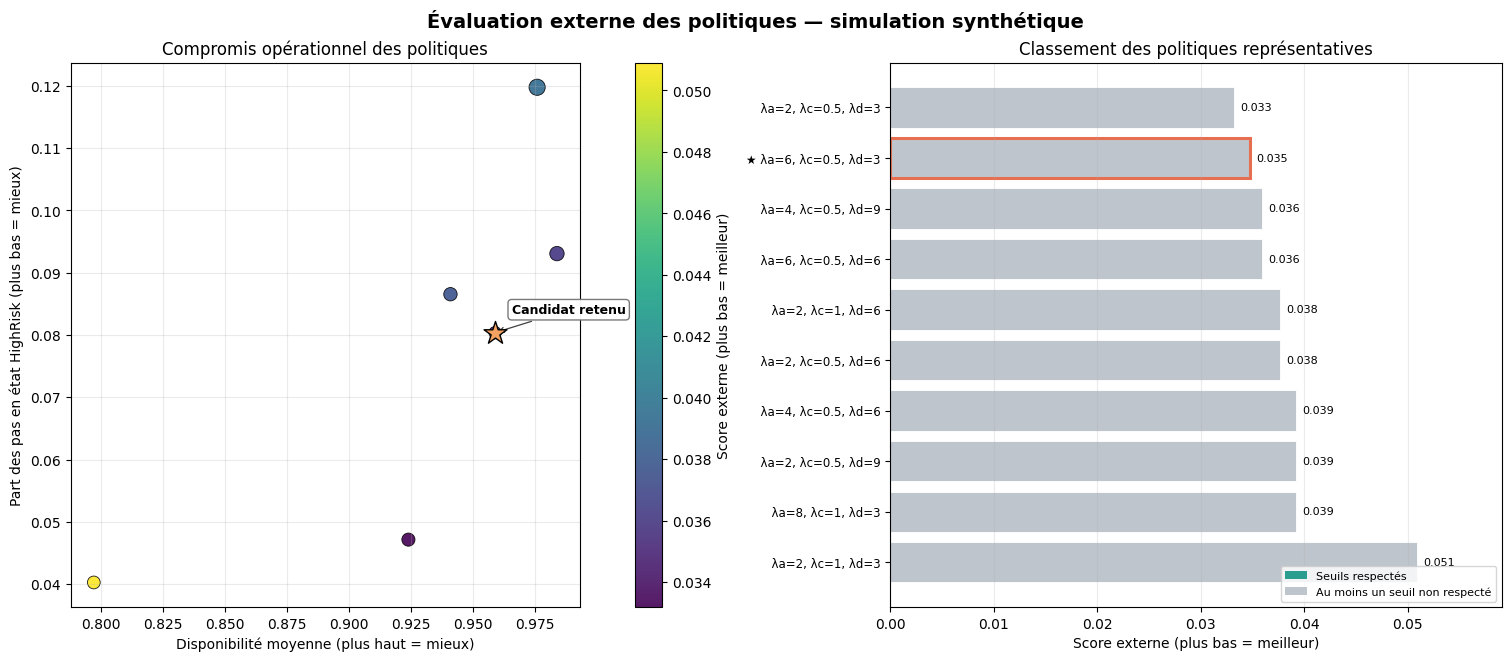

Nombre de politiques résumées : 10
Variation de la charge de fausses isolations : 0.0 à 0.0
Candidat lambda retenu : {'security': 10.0, 'availability': 6.0, 'action_cost': 0.5, 'collateral': 3.0}


In [10]:
# Résumé lisible des politiques représentatives : pas d'étiquettes longues au-dessus des points.
chosen_mask = (
    np.isclose(policy_summary["lambda_availability"], CHOSEN_WEIGHTS.availability)
    & np.isclose(policy_summary["lambda_action_cost"], CHOSEN_WEIGHTS.action_cost)
    & np.isclose(policy_summary["lambda_collateral"], CHOSEN_WEIGHTS.collateral)
)
score_min = float(sweep_df["external_score"].min())
score_max = float(sweep_df["external_score"].max())

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 6.5), constrained_layout=True,
    gridspec_kw={"width_ratios": [1.0, 1.2]}
)
# A gauche : compromis disponibilité/risque, score externe encodé par la couleur.
point_summary = policy_summary.groupby(
    ["mean_availability", "high_risk_step_rate", "external_score", "meets_all_targets"], as_index=False
).agg(number_of_lambda_configs=("number_of_lambda_configs", "sum"))
point_sizes = 65 + 14 * np.sqrt(point_summary["number_of_lambda_configs"].clip(lower=1))
sc = ax1.scatter(
    point_summary["mean_availability"],
    point_summary["high_risk_step_rate"],
    c=point_summary["external_score"],
    s=point_sizes,
    cmap="viridis", vmin=score_min, vmax=score_max,
    edgecolors="black", linewidths=0.6, alpha=0.9,
)
if chosen_mask.any():
    chosen_row = policy_summary.loc[chosen_mask].iloc[0]
    ax1.scatter(
        [chosen_row["mean_availability"]], [chosen_row["high_risk_step_rate"]],
        marker="*", s=300, color="#f4a261", edgecolors="black", linewidths=1.0,
        zorder=5,
    )
    ax1.annotate(
        "Candidat retenu",
        (chosen_row["mean_availability"], chosen_row["high_risk_step_rate"]),
        xytext=(12, 14), textcoords="offset points",
        fontsize=9, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.45", alpha=0.95),
        arrowprops=dict(arrowstyle="->", color="0.25", lw=0.9),
    )
ax1.set_xlabel("Disponibilité moyenne (plus haut = mieux)")
ax1.set_ylabel("Part des pas en état HighRisk (plus bas = mieux)")
ax1.set_title("Compromis opérationnel des politiques")
ax1.grid(alpha=0.25)
cbar = fig.colorbar(sc, ax=ax1, pad=0.02)
cbar.set_label("Score externe (plus bas = meilleur)")

# A droite : classement avec les lambdas affichés sous une forme compacte.
ranked = policy_summary.sort_values("external_score", ascending=True).reset_index(drop=True)
y = np.arange(len(ranked))
bar_colors = []
bar_edges = []
bar_widths = []
for _, r in ranked.iterrows():
    is_chosen = (
        np.isclose(r["lambda_availability"], CHOSEN_WEIGHTS.availability)
        and np.isclose(r["lambda_action_cost"], CHOSEN_WEIGHTS.action_cost)
        and np.isclose(r["lambda_collateral"], CHOSEN_WEIGHTS.collateral)
    )
    bar_colors.append("#2a9d8f" if bool(r["meets_all_targets"]) else "#bfc5cc")
    bar_edges.append("#e76f51" if is_chosen else "white")
    bar_widths.append(2.2 if is_chosen else 0.6)
labels = []
for _, r in ranked.iterrows():
    is_chosen = (
        np.isclose(r["lambda_availability"], CHOSEN_WEIGHTS.availability)
        and np.isclose(r["lambda_action_cost"], CHOSEN_WEIGHTS.action_cost)
        and np.isclose(r["lambda_collateral"], CHOSEN_WEIGHTS.collateral)
    )
    prefix = "★ " if is_chosen else ("✓ " if bool(r["meets_all_targets"]) else "  ")
    labels.append(prefix + f"λa={r['lambda_availability']:g}, λc={r['lambda_action_cost']:g}, λd={r['lambda_collateral']:g}")
for yi, (_, r) in enumerate(ranked.iterrows()):
    ax2.barh(yi, r["external_score"], color=bar_colors[yi], edgecolor=bar_edges[yi], linewidth=bar_widths[yi])
ax2.set_yticks(y, labels, fontsize=8.5)
ax2.invert_yaxis()
ax2.set_xlim(0, max(score_max * 1.16, float(ranked["external_score"].max()) * 1.1))
for yi, score in zip(y, ranked["external_score"]):
    ax2.text(score + score_max * 0.012, yi, f"{score:.3f}", va="center", fontsize=8)
ax2.set_xlabel("Score externe (plus bas = meilleur)")
ax2.set_title("Classement des politiques représentatives")
ax2.grid(axis="x", alpha=0.25)
from matplotlib.patches import Patch
legend_handles = [Patch(facecolor="#2a9d8f", label="Seuils respectés"),
                  Patch(facecolor="#bfc5cc", label="Au moins un seuil non respecté")]
ax2.legend(handles=legend_handles, loc="lower right", fontsize=8)
fig.suptitle("Évaluation externe des politiques — simulation synthétique", fontsize=14, fontweight="bold")
fig.savefig(os.path.join(FIG_DIR, "00_policy_summary_clean.png"), dpi=200, bbox_inches="tight")
plt.show()

print("Nombre de politiques résumées :", len(policy_summary))
print("Variation de la charge de fausses isolations :", float(policy_summary["false_isolation_burden"].min()), "à", float(policy_summary["false_isolation_burden"].max()))
print("Candidat lambda retenu :", asdict(CHOSEN_WEIGHTS))

## 10.1. Visualisations pour justifier le choix des lambdas

Les trois cartes de chaleur utilisent **la même échelle de couleurs**, afin de comparer honnêtement les scores entre valeurs de coût d'action. Chaque cellule affiche le score externe : une coche indique que les seuils expérimentaux sont respectés et une étoile identifie le candidat retenu. Le graphique de compromis réutilise une seule échelle pour les 45 combinaisons ; les points sont regroupés par résultats opérationnels afin de réduire le chevauchement. La taille du point représente le nombre de configurations donnant le même résultat. Les seuils restent des critères de démonstration à valider, pas des normes universelles.

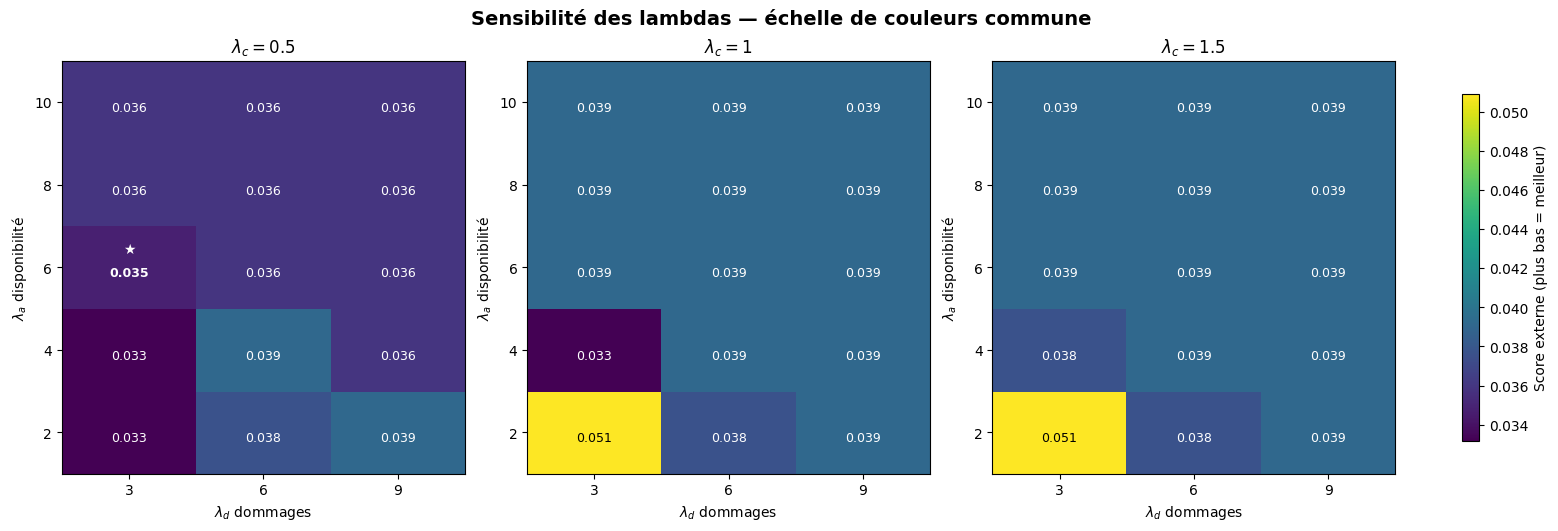

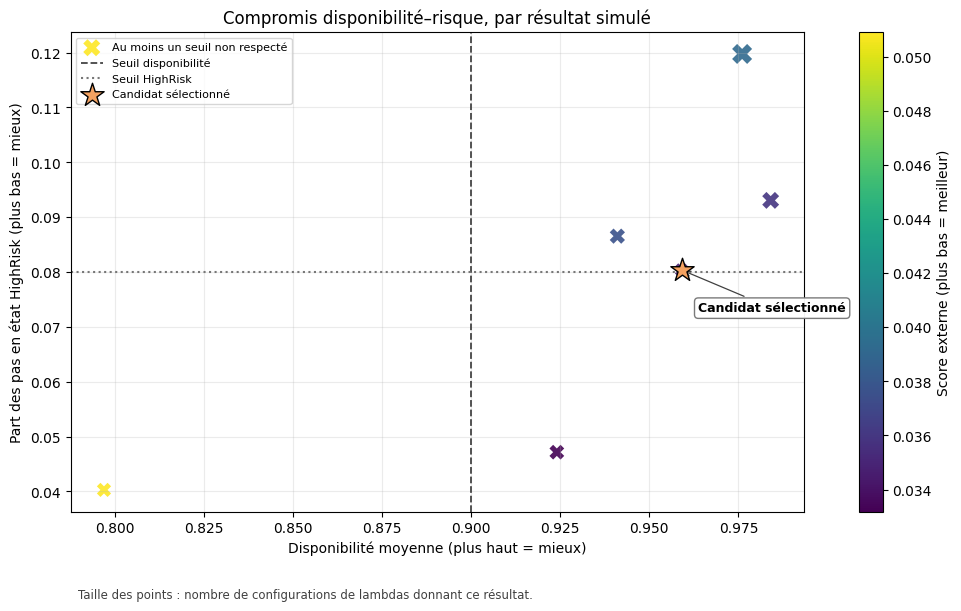

Candidat lambdas : {'security': 10.0, 'availability': 6.0, 'action_cost': 0.5, 'collateral': 3.0}
Score externe : 0.03472 | seuils respectés : False


In [11]:
chosen_tuple = (CHOSEN_WEIGHTS.security, CHOSEN_WEIGHTS.availability, CHOSEN_WEIGHTS.action_cost, CHOSEN_WEIGHTS.collateral)
score_min = float(sweep_df["external_score"].min())
score_max = float(sweep_df["external_score"].max())

# Les trois panneaux partagent les mêmes limites de couleurs.
fig, axes = plt.subplots(1, len(LAMBDA_ACTION_COST_GRID), figsize=(15.5, 5.2), constrained_layout=True)
for ax, lambda_cost in zip(axes, LAMBDA_ACTION_COST_GRID):
    part = sweep_df[np.isclose(sweep_df["lambda_action_cost"], lambda_cost)]
    pv = part.pivot(index="lambda_availability", columns="lambda_collateral", values="external_score").sort_index()
    im = ax.imshow(
        pv.values, origin="lower", aspect="auto", cmap="viridis",
        vmin=score_min, vmax=score_max, interpolation="nearest"
    )
    ax.set_xticks(range(len(pv.columns)), [f"{v:g}" for v in pv.columns])
    ax.set_yticks(range(len(pv.index)), [f"{v:g}" for v in pv.index])
    ax.set_xlabel(r"$\lambda_d$ dommages")
    ax.set_ylabel(r"$\lambda_a$ disponibilité")
    ax.set_title(rf"$\lambda_c={lambda_cost:g}$")
    for iy, la in enumerate(pv.index):
        for ix, ld in enumerate(pv.columns):
            r = part[np.isclose(part["lambda_availability"], la) & np.isclose(part["lambda_collateral"], ld)].iloc[0]
            selected = (
                np.isclose(r["lambda_availability"], chosen_tuple[1])
                and np.isclose(r["lambda_action_cost"], chosen_tuple[2])
                and np.isclose(r["lambda_collateral"], chosen_tuple[3])
            )
            value = float(pv.loc[la, ld])
            scaled = (value - score_min) / (score_max - score_min + 1e-12)
            text_color = "white" if scaled < 0.45 else "black"
            ax.text(ix, iy - 0.07, f"{value:.3f}", ha="center", va="center",
                    fontsize=9, fontweight="bold" if selected else "normal", color=text_color)
            mark = "★" if selected else ("✓" if bool(r["meets_all_targets"]) else "")
            if mark:
                ax.text(ix, iy + 0.22, mark, ha="center", va="center", fontsize=10,
                        color=text_color, fontweight="bold")

fig.colorbar(im, ax=axes, shrink=0.84, label="Score externe (plus bas = meilleur)")
fig.suptitle("Sensibilité des lambdas — échelle de couleurs commune", fontsize=14, fontweight="bold")
fig.savefig(os.path.join(FIG_DIR, "01_lambda_heatmaps.png"), dpi=200, bbox_inches="tight")
plt.show()

# Graphique de compromis : on regroupe les résultats identiques/équivalents et on ne dessine pas les longues politiques.
tradeoff = policy_summary.groupby(
    ["mean_availability", "high_risk_step_rate", "external_score", "meets_all_targets"], as_index=False
).agg(number_of_lambda_configs=("number_of_lambda_configs", "sum"))
tradeoff["marker_size"] = 65 + 28 * np.sqrt(tradeoff["number_of_lambda_configs"].clip(lower=1))
fig, ax = plt.subplots(figsize=(9.5, 6.0), constrained_layout=True)
plot_sc = None
for feasible, marker, label in [(True, "o", "Seuils respectés"), (False, "X", "Au moins un seuil non respecté")]:
    part = tradeoff[tradeoff["meets_all_targets"] == feasible]
    if part.empty:
        continue
    plot_sc = ax.scatter(
        part["mean_availability"], part["high_risk_step_rate"],
        c=part["external_score"], s=part["marker_size"], cmap="viridis",
        vmin=score_min, vmax=score_max, marker=marker,
        edgecolors="black" if marker == "o" else "none", linewidths=0.6,
        alpha=0.9, label=label,
    )
ax.axvline(OPERATIONAL_TARGETS["minimum_mean_availability"], color="#444444", linestyle="--", linewidth=1.3,
           label="Seuil disponibilité")
ax.axhline(OPERATIONAL_TARGETS["maximum_high_risk_step_rate"], color="#777777", linestyle=":", linewidth=1.5,
           label="Seuil HighRisk")
chosen = policy_summary[
    np.isclose(policy_summary["lambda_availability"], CHOSEN_WEIGHTS.availability)
    & np.isclose(policy_summary["lambda_action_cost"], CHOSEN_WEIGHTS.action_cost)
    & np.isclose(policy_summary["lambda_collateral"], CHOSEN_WEIGHTS.collateral)
].iloc[0]
ax.scatter([chosen["mean_availability"]], [chosen["high_risk_step_rate"]], marker="*", s=310,
           color="#f4a261", edgecolors="black", linewidths=1.0, label="Candidat sélectionné", zorder=6)
ax.annotate(
    "Candidat sélectionné", (chosen["mean_availability"], chosen["high_risk_step_rate"]),
    xytext=(12, -30), textcoords="offset points", fontsize=9, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.45", alpha=0.95),
    arrowprops=dict(arrowstyle="->", color="0.25", lw=0.9),
)
ax.set_xlabel("Disponibilité moyenne (plus haut = mieux)")
ax.set_ylabel("Part des pas en état HighRisk (plus bas = mieux)")
ax.set_title("Compromis disponibilité–risque, par résultat simulé")
ax.grid(alpha=0.25)
ax.legend(fontsize=8, loc="best")
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(vmin=score_min, vmax=score_max))
sm.set_array([])
fig.colorbar(sm, ax=ax, pad=0.02, label="Score externe (plus bas = meilleur)")
ax.text(0.01, -0.18, "Taille des points : nombre de configurations de lambdas donnant ce résultat.",
        transform=ax.transAxes, fontsize=8.5, color="0.25")
fig.savefig(os.path.join(FIG_DIR, "02_lambda_tradeoffs.png"), dpi=200, bbox_inches="tight")
plt.show()
print("Candidat lambdas :", asdict(CHOSEN_WEIGHTS))
print("Score externe :", round(float(chosen["external_score"]), 5), "| seuils respectés :", bool(chosen["meets_all_targets"]))

## 11. Q-learning tabulaire et choix des hyperparamètres

Le Q-learning est comparé à la solution exacte obtenue par Value Iteration. Un plan factoriel fait varier **alpha**, **gamma** et deux calendriers de **epsilon**. Chaque combinaison est évaluée sur plusieurs graines. Tous les résultats restent conditionnels au simulateur synthétique.


**Choix méthodologiques :** (0) Les épisodes démarrent dans un état tiré uniformément (*exploring starts*) afin que tous les états soient visités. (1) γ est fixé à `GAMMA_DEFAULT` pour la sélection, car il définit le problème et non l'algorithme ; les autres valeurs de γ ne servent qu'à tester la robustesse. (2) Le regret est moyenné sur **tous les états**, pas seulement les états de départ, et l'accord de politique est complété par le taux d'actions quasi optimales (écart < 0,05), qui ne pénalise pas les quasi-égalités. (3) Les graines de sélection (0 à 4) et d'évaluation finale (100 à 109) sont distinctes.

In [12]:
def choose_epsilon(episode, schedule, n_episodes):
    # Plancher epsilon=0.05 ; la variante inverse-temps ci-dessous n'est pas GLIE stricte.
    if schedule == "exponential":
        return max(0.05, float(np.exp(-episode / max(1.0, n_episodes / 5.0))))
    if schedule == "harmonic":
        return max(0.05, float(1.0 / (1.0 + episode / 60.0)))
    raise ValueError(f"Schedule inconnu : {schedule}")

def initial_value(values):
    return float(0.5 * values[STATE_TO_ID[(N, "Standard")]] + 0.5 * values[STATE_TO_ID[(N, "Critical")]])

def policy_gap(pol, weights, gamma, exact_values, exact_policy, tol=0.05):
    """Écart d'une politique apprise à la solution exacte, mesuré sur TOUS les états (pas seulement l'état initial)."""
    vals = evaluate_policy_value(pol, weights, gamma=gamma)
    gaps = np.maximum(0.0, exact_values - vals)
    near = [q_value(s, exact_policy[s], exact_values, weights, gamma) - q_value(s, pol[s], exact_values, weights, gamma) <= tol
            for s in range(N_STATES)]
    return {
        "value_regret": float(np.mean(gaps)),          # regret moyen sur les 10 états
        "max_state_regret": float(np.max(gaps)),       # pire état
        "start_regret": max(0.0, initial_value(exact_values) - initial_value(vals)),  # ancienne mesure (états de départ)
        "action_agreement": float(np.mean([pol[s] == exact_policy[s] for s in range(N_STATES)])),
        "near_optimal_action_rate": float(np.mean(near)),  # action apprise à moins de tol de l'optimum (gère les quasi-égalités)
    }, vals

def greedy_policy_from_q(Q):
    policy = {}
    for state in range(N_STATES):
        allowed = VALID_ACTIONS[state]
        values = Q[state, allowed]
        best_value = np.max(values)
        best_actions = [a for a in allowed if np.isclose(Q[state, a], best_value)]
        policy[state] = int(min(best_actions))
    return policy

# Pré-calcul des transitions et récompenses : l'environnement reste le même, mais l'entraînement est nettement plus rapide.
_TRANSITION_CACHE = {}
def transition_cache_for(weights):
    key = (weights.security, weights.availability, weights.action_cost, weights.collateral)
    if key not in _TRANSITION_CACHE:
        cache = {}
        for sid, (status, crit) in enumerate(STATES):
            for aid in VALID_ACTIONS[sid]:
                cumulative = 0.0
                opts = []
                for o in TRANSITIONS[(status, ACTIONS[aid])]:
                    cumulative += float(o["p"])
                    ns = STATE_TO_ID[(o["next_status"], crit)]
                    rew = compute_reward(sid, ACTIONS[aid], o, weights)
                    opts.append((cumulative, ns, rew))
                cache[(sid, aid)] = opts
        _TRANSITION_CACHE[key] = cache
    return _TRANSITION_CACHE[key]

def train_q_learning(weights, alpha=0.1, gamma=0.95, n_episodes=800, max_steps=40,
                     seed=0, epsilon_schedule="exponential", checkpoints=None, exploring_starts=True):
    rng = np.random.default_rng(seed)
    Q = np.zeros((N_STATES, N_ACTIONS), dtype=float)
    transition_cache = transition_cache_for(weights)
    checkpoints = set(checkpoints or [])
    history = []
    exact_values, exact_policy, _ = value_iteration(weights, gamma=gamma) if checkpoints else (None, None, None)
    exact_start = initial_value(exact_values) if checkpoints else None
    for episode in range(n_episodes):
        if exploring_starts:
            # Départs dans n'importe quel état : depuis Normal seul, Isolated et VerifiedSafe sont rarement visités,
            # leurs Q restent à 0 et la politique y est fixée arbitrairement (cause du blocage en VerifiedSafe).
            state = int(rng.integers(N_STATES))
        else:
            crit = ASSET_CRITICALITY[int(rng.integers(len(ASSET_CRITICALITY)))]
            state = STATE_TO_ID[(N, crit)]
        eps = choose_epsilon(episode, epsilon_schedule, n_episodes)
        for _ in range(max_steps):
            allowed = VALID_ACTIONS[state]
            if rng.random() < eps:
                action_id = int(allowed[int(rng.integers(len(allowed)))])
            else:
                action_id = int(allowed[int(np.argmax(Q[state, allowed]))])
            draw = rng.random()
            selected = transition_cache[(state, action_id)][-1]
            for cumulative, ns, rew in transition_cache[(state, action_id)]:
                if draw <= cumulative:
                    selected = (cumulative, ns, rew)
                    break
            _, next_state, reward = selected
            next_allowed = VALID_ACTIONS[next_state]
            target = reward + gamma * float(np.max(Q[next_state, next_allowed]))
            Q[state, action_id] += alpha * (target - Q[state, action_id])
            state = next_state
        completed = episode + 1
        if completed in checkpoints:
            pol = greedy_policy_from_q(Q)
            gap, _ = policy_gap(pol, weights, gamma, exact_values, exact_policy)
            history.append({"episode": completed, "seed": seed, "alpha": alpha, "gamma": gamma,
                            "epsilon_schedule": epsilon_schedule, **gap})
    return (Q, history) if checkpoints else Q

ALPHA_GRID = [0.05, 0.10, 0.20]
GAMMA_GRID = [0.90, 0.95, 0.99]
EPSILON_SCHEDULES = ["exponential", "harmonic"]
CONFIGS = [{"alpha": a, "gamma": g, "epsilon_schedule": e}
           for a, g, e in product(ALPHA_GRID, GAMMA_GRID, EPSILON_SCHEDULES)]
# Séparation des graines : sélection des hyperparamètres (0 à 4) ≠ évaluation finale (100 à 109, jamais utilisées pour choisir).
N_TRAIN_SEEDS = 5
SELECTION_SEEDS = list(range(N_TRAIN_SEEDS))
EVAL_SEEDS = list(range(100, 110))
# γ définit le problème : on sélectionne alpha et epsilon à γ fixé. Les autres γ ne servent qu'à l'analyse de robustesse.
SELECTION_GAMMA = GAMMA_DEFAULT
TRAIN_EPISODES = 1000  # budget augmenté (220 épisodes ne suffisaient pas à converger)
TRAIN_HORIZON = 30
training_rows = []
for cfg_id, cfg in enumerate(CONFIGS, start=1):
    print(f"Configuration {cfg_id}/{len(CONFIGS)} : {cfg}", flush=True)
    exact_values, exact_policy, _ = value_iteration(CHOSEN_WEIGHTS, gamma=cfg["gamma"])
    exact_start_value = initial_value(exact_values)
    for seed in SELECTION_SEEDS:
        q_table = train_q_learning(CHOSEN_WEIGHTS, alpha=cfg["alpha"], gamma=cfg["gamma"],
            n_episodes=TRAIN_EPISODES, max_steps=TRAIN_HORIZON, seed=seed,
            epsilon_schedule=cfg["epsilon_schedule"])
        learned_policy = greedy_policy_from_q(q_table)
        gap, learned_values = policy_gap(learned_policy, CHOSEN_WEIGHTS, cfg["gamma"], exact_values, exact_policy)
        training_rows.append({**cfg, "seed": seed, "learned_start_value": initial_value(learned_values),
            "optimal_start_value": exact_start_value, **gap, "policy": policy_label(learned_policy)})
training_df = pd.DataFrame(training_rows)
training_summary = training_df.groupby(["alpha", "gamma", "epsilon_schedule"], as_index=False).agg(
    mean_value_regret=("value_regret", "mean"), std_value_regret=("value_regret", "std"),
    mean_max_state_regret=("max_state_regret", "mean"), mean_start_regret=("start_regret", "mean"),
    mean_action_agreement=("action_agreement", "mean"), std_action_agreement=("action_agreement", "std"),
    mean_near_optimal_rate=("near_optimal_action_rate", "mean"),
    mean_learned_value=("learned_start_value", "mean"))
display(training_summary.sort_values("mean_value_regret").round(4))
print(f"Runs d'apprentissage : {len(training_df)} ({N_TRAIN_SEEDS} graines x {len(CONFIGS)} configurations).")
print("Regret = moyenne sur les 10 états de max(0, V* - V_pi) ; start_regret = ancienne mesure limitée aux états de départ.")


Configuration 1/18 : {'alpha': 0.05, 'gamma': 0.9, 'epsilon_schedule': 'exponential'}
Configuration 2/18 : {'alpha': 0.05, 'gamma': 0.9, 'epsilon_schedule': 'harmonic'}
Configuration 3/18 : {'alpha': 0.05, 'gamma': 0.95, 'epsilon_schedule': 'exponential'}
Configuration 4/18 : {'alpha': 0.05, 'gamma': 0.95, 'epsilon_schedule': 'harmonic'}
Configuration 5/18 : {'alpha': 0.05, 'gamma': 0.99, 'epsilon_schedule': 'exponential'}
Configuration 6/18 : {'alpha': 0.05, 'gamma': 0.99, 'epsilon_schedule': 'harmonic'}
Configuration 7/18 : {'alpha': 0.1, 'gamma': 0.9, 'epsilon_schedule': 'exponential'}
Configuration 8/18 : {'alpha': 0.1, 'gamma': 0.9, 'epsilon_schedule': 'harmonic'}
Configuration 9/18 : {'alpha': 0.1, 'gamma': 0.95, 'epsilon_schedule': 'exponential'}
Configuration 10/18 : {'alpha': 0.1, 'gamma': 0.95, 'epsilon_schedule': 'harmonic'}
Configuration 11/18 : {'alpha': 0.1, 'gamma': 0.99, 'epsilon_schedule': 'exponential'}
Configuration 12/18 : {'alpha': 0.1, 'gamma': 0.99, 'epsilon_sche

,alpha,gamma,epsilon_schedule,mean_value_regret,std_value_regret,mean_max_state_regret,mean_start_regret,mean_action_agreement,std_action_agreement,mean_near_optimal_rate,mean_learned_value
6,0.10,0.90,exponential,0.0439,0.0277,0.1963,0.0118,0.86,0.0548,0.88,-0.8618
12,0.20,0.90,exponential,0.0811,0.0415,0.2824,0.0341,0.80,0.0707,0.84,-0.8841
13,0.20,0.90,harmonic,0.0875,0.1190,0.2981,0.0000,0.86,0.1342,0.86,-0.8500
7,0.10,0.90,harmonic,0.0975,0.0342,0.3551,0.0000,0.78,0.0837,0.78,-0.8500
8,0.10,0.95,exponential,0.1331,0.0411,0.2477,0.1208,0.56,0.1517,0.92,-1.6364
0,0.05,0.90,exponential,0.1429,0.0974,0.5051,0.0300,0.74,0.0894,0.78,-0.8800
1,0.05,0.90,harmonic,0.1482,0.1163,0.6088,0.0316,0.80,0.0707,0.82,-0.8816
14,0.20,0.95,exponential,0.2084,0.0915,0.5855,0.1612,0.56,0.0894,0.86,-1.6768
15,0.20,0.95,harmonic,0.2374,0.1212,0.6831,0.1801,0.56,0.0548,0.88,-1.6957
3,0.05,0.95,harmonic,0.2572,0.0737,0.7168,0.1573,0.52,0.0447,0.82,-1.6729


Runs d'apprentissage : 90 (5 graines x 18 configurations).
Regret = moyenne sur les 10 états de max(0, V* - V_pi) ; start_regret = ancienne mesure limitée aux états de départ.


## 12. Visualiser la stabilité de Q-learning

Les cartes de chaleur permettent de comparer l'ensemble des configurations sans surcharger l'axe horizontal avec 18 étiquettes. Les lignes représentent les valeurs de **alpha**, les colonnes celles de **gamma**, et chaque panneau correspond à un calendrier de **epsilon**. Le regret est affiché sur une échelle logarithmique en raison de son étendue ; l'accord de politique est affiché sur une échelle linéaire de 0 à 1. Les valeurs dans les cellules sont les moyennes sur cinq graines.

Axes de regret : moyenne sur les 10 états. Les valeurs de γ ≠ 0,95 sont des vérifications de robustesse : regrets et valeurs ne sont pas comparables entre γ, car chaque γ définit un problème différent.

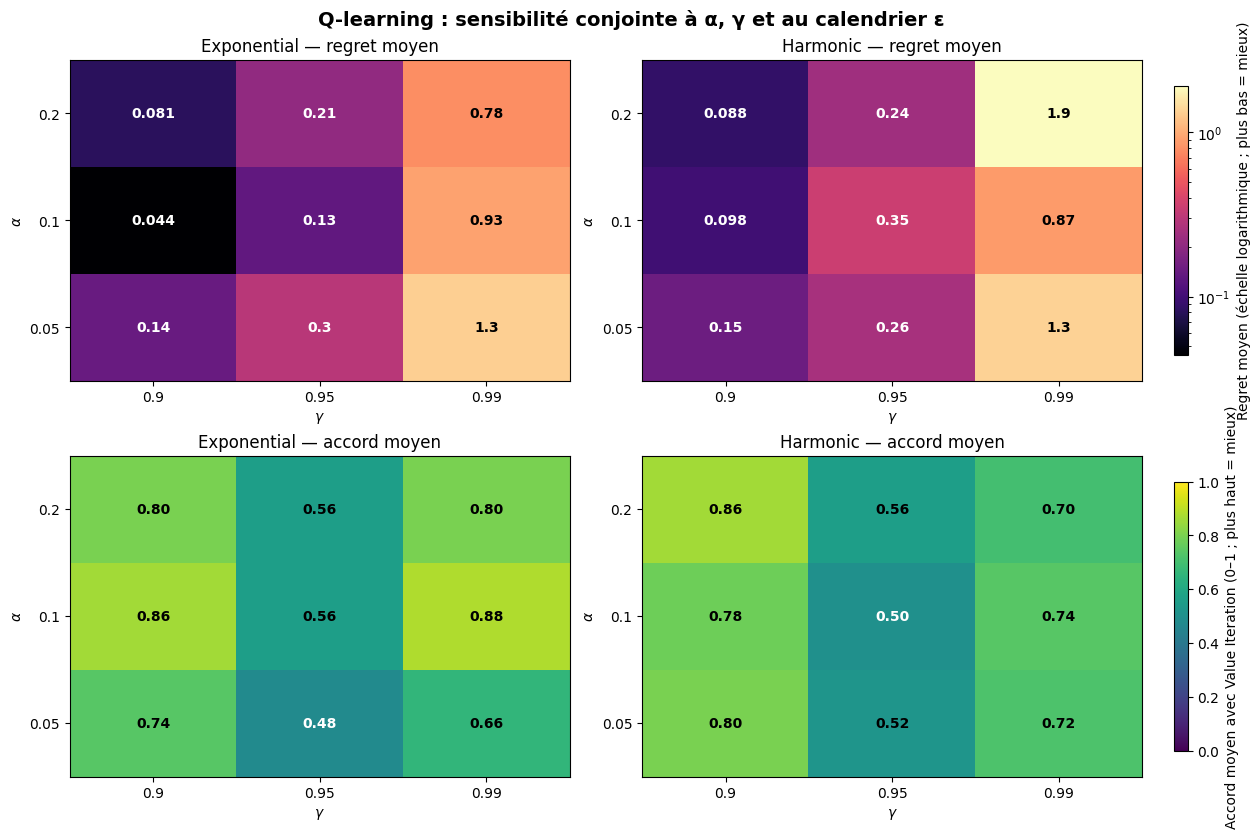

In [13]:
from matplotlib.colors import LogNorm

# Deux lignes de métriques × deux calendriers epsilon : la grille rend les 18 configurations lisibles.
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.2), constrained_layout=True)
schedules = ["exponential", "harmonic"]
regret_values = training_summary["mean_value_regret"].to_numpy(dtype=float)
regret_positive = regret_values[regret_values > 0]
regret_norm = LogNorm(vmin=float(regret_positive.min()), vmax=float(regret_positive.max()))

for col_idx, schedule in enumerate(schedules):
    subset = training_summary[training_summary["epsilon_schedule"] == schedule]
    regret_pv = subset.pivot(index="alpha", columns="gamma", values="mean_value_regret").sort_index()
    agree_pv = subset.pivot(index="alpha", columns="gamma", values="mean_action_agreement").sort_index()
    im_regret = axes[0, col_idx].imshow(regret_pv.values, origin="lower", aspect="auto", cmap="magma", norm=regret_norm)
    im_agreement = axes[1, col_idx].imshow(agree_pv.values, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=1)
    for ax, pv, metric in [(axes[0, col_idx], regret_pv, "regret"), (axes[1, col_idx], agree_pv, "agreement")]:
        ax.set_xticks(range(len(pv.columns)), [f"{v:g}" for v in pv.columns])
        ax.set_yticks(range(len(pv.index)), [f"{v:g}" for v in pv.index])
        ax.set_xlabel(r"$\gamma$")
        ax.set_ylabel(r"$\alpha$")
        ax.set_title(f"{schedule.capitalize()} — " + ("regret moyen" if metric == "regret" else "accord moyen"))
        for iy in range(len(pv.index)):
            for ix in range(len(pv.columns)):
                val = float(pv.iloc[iy, ix])
                txt = f"{val:.2g}" if metric == "regret" else f"{val:.2f}"
                text_color = ("white" if float(regret_norm(val)) < 0.58 else "black") if metric == "regret" else ("white" if val < 0.52 else "black")
                ax.text(ix, iy, txt, ha="center", va="center", fontsize=10, fontweight="bold", color=text_color)
    axes[0, col_idx].set_xlabel(r"$\gamma$")
    axes[1, col_idx].set_xlabel(r"$\gamma$")

fig.colorbar(im_regret, ax=axes[0, :], shrink=0.84, pad=0.03, label="Regret moyen (échelle logarithmique ; plus bas = mieux)")
fig.colorbar(im_agreement, ax=axes[1, :], shrink=0.84, pad=0.03, label="Accord moyen avec Value Iteration (0–1 ; plus haut = mieux)")
fig.suptitle("Q-learning : sensibilité conjointe à α, γ et au calendrier ε", fontsize=14, fontweight="bold")
fig.savefig(os.path.join(FIG_DIR, "03_hyperparameter_heatmaps.png"), dpi=200, bbox_inches="tight")
plt.show()

### 12.1. Comparaisons contrôlées : alpha, gamma et epsilon

Chaque panneau fait varier un paramètre tout en gardant les deux autres constants. Les barres d'erreur sont l'écart-type entre les 5 graines, pas un intervalle de confiance. Un regret plus faible et un accord de politique plus élevé sont préférables ; ils donnent deux angles de lecture complémentaires.


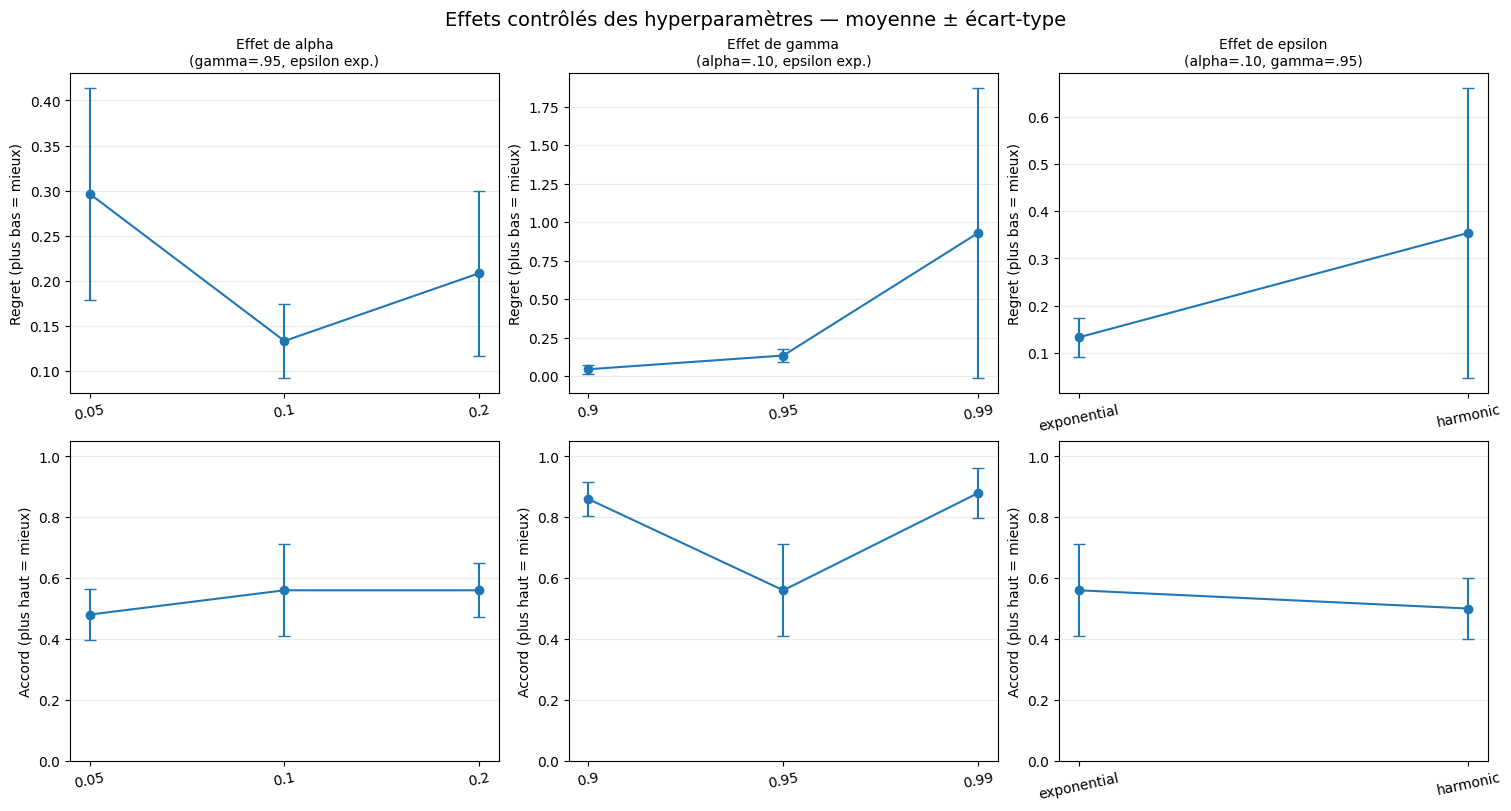

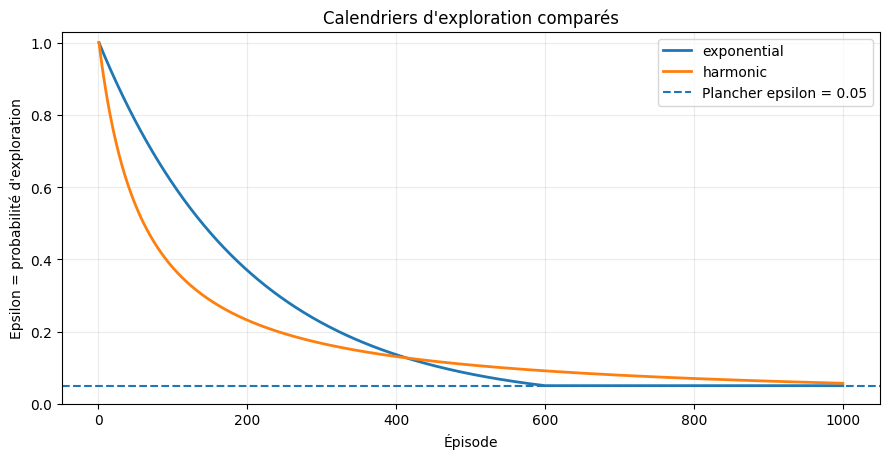

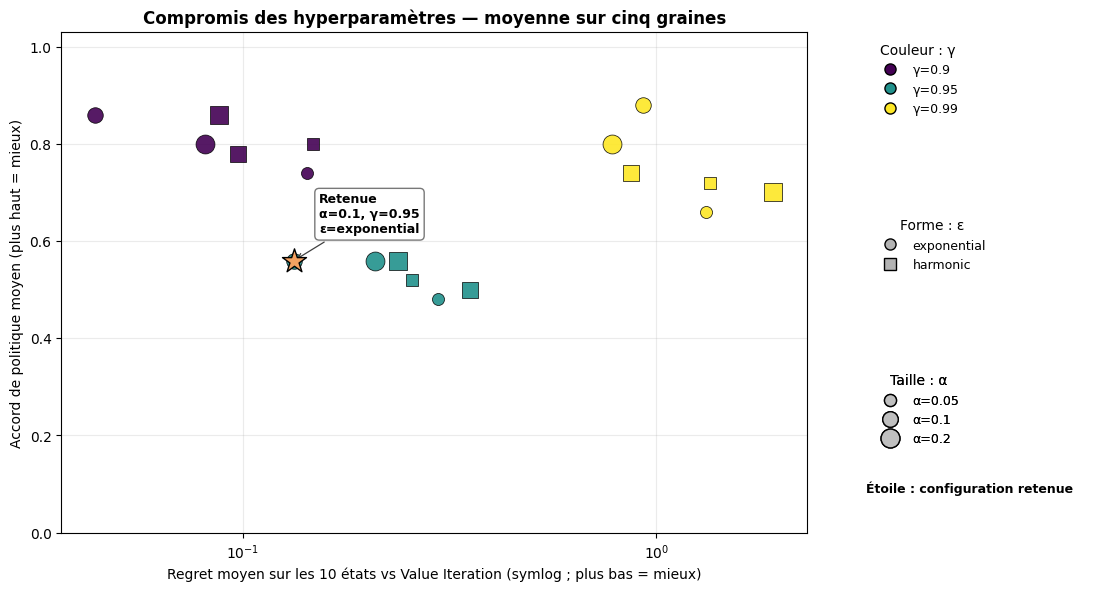

Sélection à γ = 0.95 : regret <= minimum + 0.02, puis accord de politique maximal.
Configuration retenue selon cette règle multi-critère : {'alpha': np.float64(0.1), 'gamma': np.float64(0.95), 'epsilon_schedule': 'exponential', 'mean_value_regret': np.float64(0.13314118415150075), 'std_value_regret': np.float64(0.0410604609395467), 'mean_action_agreement': np.float64(0.5599999999999999)}


In [14]:
def summarize_slice(df, col):
    return df.groupby(col).agg(regret=("value_regret", "mean"), regret_sd=("value_regret", "std"),
        agreement=("action_agreement", "mean"), agreement_sd=("action_agreement", "std")).reset_index()
alpha_slice = summarize_slice(training_df[np.isclose(training_df.gamma, .95) & (training_df.epsilon_schedule == "exponential")], "alpha")
gamma_slice = summarize_slice(training_df[np.isclose(training_df.alpha, .10) & (training_df.epsilon_schedule == "exponential")], "gamma")
eps_slice = summarize_slice(training_df[np.isclose(training_df.alpha, .10) & np.isclose(training_df.gamma, .95)], "epsilon_schedule")
slices = [(alpha_slice,"alpha","Effet de alpha\n(gamma=.95, epsilon exp.)"),
          (gamma_slice,"gamma","Effet de gamma\n(alpha=.10, epsilon exp.)"),
          (eps_slice,"epsilon_schedule","Effet de epsilon\n(alpha=.10, gamma=.95)")]
fig, axes = plt.subplots(2,3,figsize=(15,8),constrained_layout=True)
for j,(df,col,title) in enumerate(slices):
    x=np.arange(len(df)); labels=[f"{v:g}" if isinstance(v,(int,float,np.number)) else str(v) for v in df[col]]
    axes[0,j].errorbar(x,df.regret,yerr=df.regret_sd.fillna(0),marker="o",capsize=4)
    axes[0,j].set_xticks(x,labels,rotation=12); axes[0,j].set_title(title,fontsize=10)
    axes[0,j].set_ylabel("Regret (plus bas = mieux)"); axes[0,j].grid(axis="y",alpha=.25)
    axes[1,j].errorbar(x,df.agreement,yerr=df.agreement_sd.fillna(0),marker="o",capsize=4)
    axes[1,j].set_xticks(x,labels,rotation=12); axes[1,j].set_ylabel("Accord (plus haut = mieux)")
    axes[1,j].set_ylim(0,1.05); axes[1,j].grid(axis="y",alpha=.25)
fig.suptitle("Effets contrôlés des hyperparamètres — moyenne ± écart-type",fontsize=14)
fig.savefig(os.path.join(FIG_DIR,"03_hyperparameter_controlled_effects.png"),dpi=180,bbox_inches="tight")
plt.show()

# Courbes epsilon pour justifier visuellement la stratégie d'exploration.
episodes=np.arange(TRAIN_EPISODES)
fig,ax=plt.subplots(figsize=(9,4.7))
for schedule in EPSILON_SCHEDULES:
    ax.plot(episodes+1,[choose_epsilon(int(e),schedule,TRAIN_EPISODES) for e in episodes],label=schedule,linewidth=2)
ax.axhline(.05,linestyle="--",label="Plancher epsilon = 0.05")
ax.set_xlabel("Épisode"); ax.set_ylabel("Epsilon = probabilité d'exploration")
ax.set_title("Calendriers d'exploration comparés"); ax.set_ylim(0,1.03); ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR,"04_epsilon_schedules.png"),dpi=180,bbox_inches="tight"); plt.show()

# Règle de sélection multi-critère : regret proche du minimum, puis meilleur accord moyen.
REGRET_TOLERANCE = 0.02
selection_table = training_summary[np.isclose(training_summary["gamma"], SELECTION_GAMMA)]  # γ fixé : on ne choisit pas γ par le regret
minimum_regret = float(selection_table["mean_value_regret"].min())
near_optimal = selection_table[selection_table["mean_value_regret"] <= minimum_regret + REGRET_TOLERANCE].copy()
best_hyperparams = near_optimal.sort_values(
    ["mean_action_agreement", "std_value_regret"], ascending=[False, True]
).iloc[0]

# Nuage de compromis lisible : couleur = gamma, forme = calendrier epsilon, taille = alpha.
# Les écarts-types par graine sont présentés dans les graphiques contrôlés juste au-dessus.
from matplotlib.lines import Line2D

gamma_values = sorted(training_summary["gamma"].unique())
gamma_cmap = plt.get_cmap("viridis")
gamma_colors = {g: gamma_cmap(i / max(1, len(gamma_values) - 1)) for i, g in enumerate(gamma_values)}
marker_by_schedule = {"exponential": "o", "harmonic": "s"}
alpha_values = sorted(training_summary["alpha"].unique())
size_by_alpha = {a: s for a, s in zip(alpha_values, [75, 125, 185])}

fig = plt.figure(figsize=(13.5, 6.5))
gs = fig.add_gridspec(1, 2, width_ratios=[3.4, 1.1], wspace=0.12)
ax = fig.add_subplot(gs[0, 0])
legend_ax = fig.add_subplot(gs[0, 1])
legend_ax.axis("off")
for r in training_summary.itertuples():
    ax.scatter(
        r.mean_value_regret, r.mean_action_agreement,
        color=gamma_colors[r.gamma], marker=marker_by_schedule[r.epsilon_schedule],
        s=size_by_alpha[r.alpha], edgecolors="black", linewidths=0.55, alpha=0.9, zorder=3,
    )
ax.scatter(
    [best_hyperparams["mean_value_regret"]], [best_hyperparams["mean_action_agreement"]],
    marker="*", s=330, color="#f4a261", edgecolors="black", linewidths=1.0,
    label="Configuration retenue", zorder=6,
)
ax.annotate(
    f"Retenue\nα={best_hyperparams.alpha:g}, γ={best_hyperparams.gamma:g}\nε={best_hyperparams.epsilon_schedule}",
    (best_hyperparams["mean_value_regret"], best_hyperparams["mean_action_agreement"]),
    xytext=(18, 20), textcoords="offset points", fontsize=9, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.45", alpha=0.96),
    arrowprops=dict(arrowstyle="->", color="0.25", lw=0.9),
)
ax.set_xscale("symlog", linthresh=0.02)
ax.set_xlabel("Regret moyen sur les 10 états vs Value Iteration (symlog ; plus bas = mieux)")
ax.set_ylabel("Accord de politique moyen (plus haut = mieux)")
ax.set_title("Compromis des hyperparamètres — moyenne sur cinq graines", fontweight="bold")
ax.set_ylim(0, 1.03)
ax.grid(alpha=0.25, which="both")

# Les trois légendes restent à l'intérieur de la zone réservée à droite.
gamma_handles = [Line2D([0], [0], marker="o", linestyle="", markersize=8,
                         markerfacecolor=gamma_colors[g], markeredgecolor="black", label=f"γ={g:g}")
                 for g in gamma_values]
leg1 = legend_ax.legend(handles=gamma_handles, title="Couleur : γ", loc="upper left", frameon=False, fontsize=9)
legend_ax.add_artist(leg1)
schedule_handles = [Line2D([0], [0], marker=marker_by_schedule[s], linestyle="", markersize=8,
                            markerfacecolor="0.7", markeredgecolor="black", label=s)
                    for s in ["exponential", "harmonic"]]
leg2 = legend_ax.legend(handles=schedule_handles, title="Forme : ε", loc="upper left", bbox_to_anchor=(0, 0.65), frameon=False, fontsize=9)
legend_ax.add_artist(leg2)
alpha_handles = [Line2D([0], [0], marker="o", linestyle="", markersize=np.sqrt(size_by_alpha[a]),
                        markerfacecolor="0.75", markeredgecolor="black", label=f"α={a:g}")
                 for a in alpha_values]
leg3 = legend_ax.legend(handles=alpha_handles, title="Taille : α", loc="upper left", bbox_to_anchor=(0, 0.34), frameon=False, fontsize=9)
legend_ax.add_artist(leg3)
legend_ax.text(0.0, 0.08, "Étoile : configuration retenue", transform=legend_ax.transAxes, fontsize=9, fontweight="bold")
fig.savefig(os.path.join(FIG_DIR, "05_hyperparameter_tradeoff.png"), dpi=200, bbox_inches="tight")
plt.show()
print(f"Sélection à γ = {SELECTION_GAMMA:g} : regret <= minimum + {REGRET_TOLERANCE:.2f}, puis accord de politique maximal.")
print("Configuration retenue selon cette règle multi-critère :", {k: best_hyperparams[k] for k in ["alpha", "gamma", "epsilon_schedule", "mean_value_regret", "std_value_regret", "mean_action_agreement"]})

### 12.2. Courbes d'apprentissage : évolution du regret

Les trois configurations représentatives sont réévaluées régulièrement au cours de l'entraînement. La ligne représente le regret moyen par rapport à Value Iteration ; la zone ombrée montre ± un écart-type sur les graines. Cela permet de distinguer une bonne valeur finale d'une convergence lente ou instable.


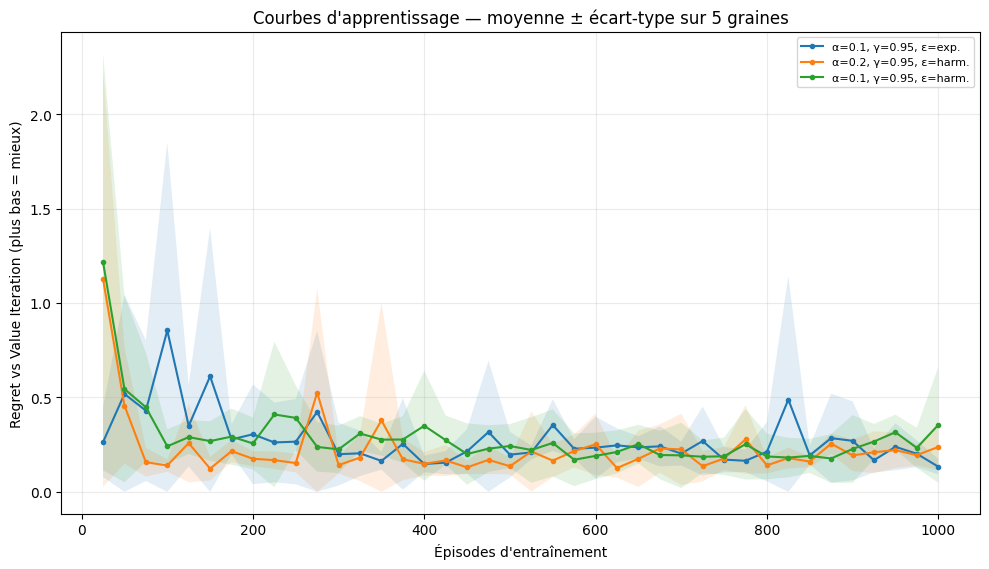

Mesures de courbe : 600


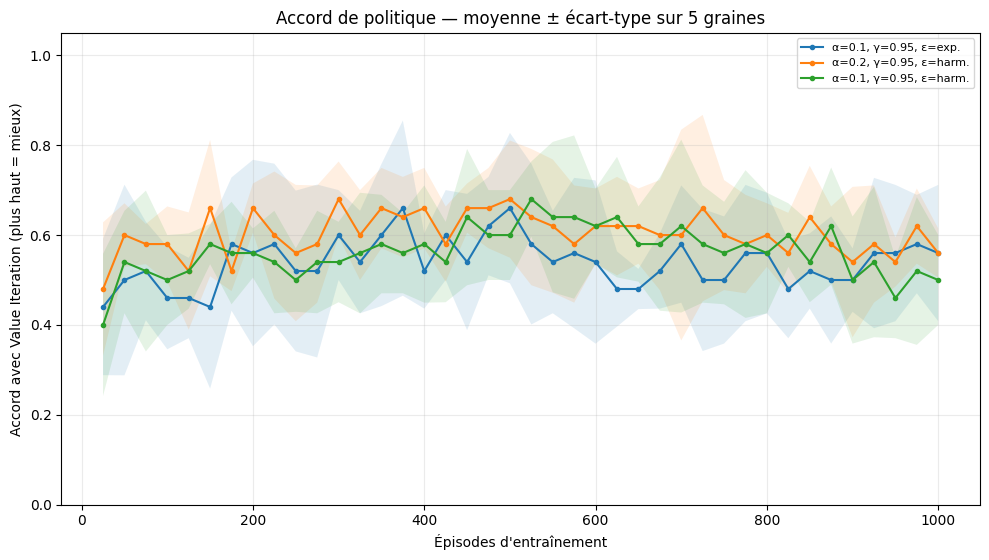

In [15]:
best_cfg={"alpha":float(best_hyperparams.alpha),"gamma":float(best_hyperparams.gamma),"epsilon_schedule":str(best_hyperparams.epsilon_schedule)}
curve_cfgs=[best_cfg,
                        {"alpha":.10,"gamma":.95,"epsilon_schedule":"exponential"},
            {"alpha":.20,"gamma":.95,"epsilon_schedule":"harmonic"},
            {"alpha":.10,"gamma":.95,"epsilon_schedule":"harmonic"}]
unique=[]; seen=set()
for cfg in curve_cfgs:
    key=(cfg["alpha"],cfg["gamma"],cfg["epsilon_schedule"])
    if key not in seen: seen.add(key); unique.append(cfg)
checkpoints=sorted(set(list(range(25,TRAIN_EPISODES+1,25))+[TRAIN_EPISODES]))
curve_rows=[]
for cfg in unique:
    for seed in SELECTION_SEEDS:
        _,hist=train_q_learning(CHOSEN_WEIGHTS,alpha=cfg["alpha"],gamma=cfg["gamma"],n_episodes=TRAIN_EPISODES,
            max_steps=TRAIN_HORIZON,seed=seed,epsilon_schedule=cfg["epsilon_schedule"],checkpoints=checkpoints)
        curve_rows.extend(hist)
learning_curve_df=pd.DataFrame(curve_rows)
curve_summary=learning_curve_df.groupby(["alpha","gamma","epsilon_schedule","episode"],as_index=False).agg(
    regret_mean=("value_regret","mean"),regret_std=("value_regret","std"),
    agreement_mean=("action_agreement","mean"),agreement_std=("action_agreement","std"))
fig,ax=plt.subplots(figsize=(10,5.8))
for cfg in unique:
    q=curve_summary[np.isclose(curve_summary.alpha,cfg["alpha"])&np.isclose(curve_summary.gamma,cfg["gamma"])&(curve_summary.epsilon_schedule==cfg["epsilon_schedule"])].sort_values("episode")
    label=f"α={cfg['alpha']:g}, γ={cfg['gamma']:g}, ε={'exp.' if cfg['epsilon_schedule']=='exponential' else 'harm.'}"
    ax.plot(q.episode,q.regret_mean,marker="o",markersize=3,label=label)
    ax.fill_between(q.episode.to_numpy(),np.maximum(0,q.regret_mean-q.regret_std.fillna(0)).to_numpy(),(q.regret_mean+q.regret_std.fillna(0)).to_numpy(),alpha=.13)
ax.set_xlabel("Épisodes d'entraînement"); ax.set_ylabel("Regret vs Value Iteration (plus bas = mieux)")
ax.set_title(f"Courbes d'apprentissage — moyenne ± écart-type sur {N_TRAIN_SEEDS} graines")
ax.grid(alpha=.25); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR,"06_learning_curves.png"),dpi=180,bbox_inches="tight"); plt.show()
print("Mesures de courbe :",len(learning_curve_df))

# Tracé de l'accord de politique en complément du regret.
fig,ax=plt.subplots(figsize=(10,5.7))
for cfg in unique:
    q=curve_summary[np.isclose(curve_summary.alpha,cfg["alpha"])&np.isclose(curve_summary.gamma,cfg["gamma"])&(curve_summary.epsilon_schedule==cfg["epsilon_schedule"])].sort_values("episode")
    label=f"α={cfg['alpha']:g}, γ={cfg['gamma']:g}, ε={'exp.' if cfg['epsilon_schedule']=='exponential' else 'harm.'}"
    ax.plot(q.episode,q.agreement_mean,marker="o",markersize=3,label=label)
    lower=np.maximum(0,q.agreement_mean-q.agreement_std.fillna(0))
    upper=np.minimum(1,q.agreement_mean+q.agreement_std.fillna(0))
    ax.fill_between(q.episode.to_numpy(),lower.to_numpy(),upper.to_numpy(),alpha=.12)
ax.set_xlabel("Épisodes d'entraînement"); ax.set_ylabel("Accord avec Value Iteration (plus haut = mieux)")
ax.set_title(f"Accord de politique — moyenne ± écart-type sur {N_TRAIN_SEEDS} graines")
ax.set_ylim(0,1.05); ax.grid(alpha=.25); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR,"07_policy_agreement_curves.png"),dpi=180,bbox_inches="tight"); plt.show()


### 12.3. Évaluation finale sur graines indépendantes

La configuration choisie ci-dessus est ré-entraînée sur 10 graines **jamais utilisées pour la sélection**. On compare la politique apprise à la politique exacte sur toutes les métriques opérationnelles, pas seulement sur le regret. Cela évite de présenter comme résultat final un score sélectionné sur les mêmes graines.

In [16]:
final_cfg = {"alpha": float(best_hyperparams.alpha), "gamma": float(best_hyperparams.gamma),
             "epsilon_schedule": str(best_hyperparams.epsilon_schedule)}
final_values, final_policy, _ = value_iteration(CHOSEN_WEIGHTS, gamma=final_cfg["gamma"])
eval_rows = []
for seed in EVAL_SEEDS:
    Qf = train_q_learning(CHOSEN_WEIGHTS, alpha=final_cfg["alpha"], gamma=final_cfg["gamma"],
                          n_episodes=TRAIN_EPISODES, max_steps=TRAIN_HORIZON, seed=seed,
                          epsilon_schedule=final_cfg["epsilon_schedule"])
    pol = greedy_policy_from_q(Qf)
    gap, _ = policy_gap(pol, CHOSEN_WEIGHTS, final_cfg["gamma"], final_values, final_policy)
    ext = evaluate_policy_exact(pol, CHOSEN_WEIGHTS, horizon=40)
    eval_rows.append({"seed": seed, **gap, **{k: ext[k] for k in
        ["mean_availability", "high_risk_step_rate", "false_alarm_burden", "false_isolation_burden",
         "max_steps_to_normal", "external_score"]}, "policy": policy_label(pol)})
final_eval_df = pd.DataFrame(eval_rows)
ref = evaluate_policy_exact(final_policy, CHOSEN_WEIGHTS, horizon=40)
metric_cols = ["value_regret", "max_state_regret", "action_agreement", "near_optimal_action_rate",
               "mean_availability", "high_risk_step_rate", "false_alarm_burden", "false_isolation_burden",
               "max_steps_to_normal", "external_score"]
with np.errstate(invalid="ignore"):
    final_summary = final_eval_df[metric_cols].replace(np.inf, np.nan).agg(["mean", "std"]).T
final_summary["Value Iteration (référence)"] = [np.nan]*4 + [ref[k] for k in metric_cols[4:]]
display(final_summary.round(4))
print("Configuration finale :", final_cfg, "| graines d'évaluation :", EVAL_SEEDS[0], "à", EVAL_SEEDS[-1])
print(f"Graines dont la politique apprise est identique à la politique exacte : "
      f"{int((final_eval_df['action_agreement'] == 1).sum())}/{len(final_eval_df)}")
print(f"Graines dont toutes les actions sont quasi optimales : "
      f"{int((final_eval_df['near_optimal_action_rate'] == 1).sum())}/{len(final_eval_df)}")

,mean,std,Value Iteration (référence)
value_regret,0.2254,0.2016,NaN
max_state_regret,0.5085,0.7182,NaN
action_agreement,0.6400,0.1075,NaN
near_optimal_action_rate,0.9100,0.0738,NaN
mean_availability,0.9873,0.0165,0.9591
high_risk_step_rate,0.0217,0.0358,0.0804
false_alarm_burden,0.7621,0.2508,0.0632
false_isolation_burden,0.0000,0.0000,0.0000
max_steps_to_normal,67.5199,64.1356,5.0000
external_score,0.1430,0.0374,0.0347


Configuration finale : {'alpha': 0.1, 'gamma': 0.95, 'epsilon_schedule': 'exponential'} | graines d'évaluation : 100 à 109
Graines dont la politique apprise est identique à la politique exacte : 0/10
Graines dont toutes les actions sont quasi optimales : 3/10


### 12.4. Diagnostic : pourquoi l'agent appris génère beaucoup de fausses alertes

Les actions de l'état `Normal` ont des valeurs presque identiques sous la reward actuelle. Un agent qui apprend avec du bruit ne peut donc pas les départager, et choisit souvent `alert`. Ce n'est pas un échec d'apprentissage : c'est une faiblesse de conception de la reward, que la Value Iteration masque en choisissant l'action légèrement meilleure.

In [17]:
rows = []
for crit in ASSET_CRITICALITY:
    s = STATE_TO_ID[(N, crit)]
    qs = {ACTIONS[a]: q_value(s, a, final_values, CHOSEN_WEIGHTS, final_cfg["gamma"]) for a in VALID_ACTIONS[s]}
    rows.append({"criticité": crit, **{f"Q({k})": v for k, v in qs.items()},
                 "écart max entre actions": max(qs.values()) - min(qs.values())})
display(pd.DataFrame(rows).round(4))
print("Si l'écart est inférieur au bruit d'apprentissage, il faut une pénalité explicite de fausse alerte "
      "(par ex. un terme lambda_fa * false_alarm dans la reward) pour que l'agent préfère monitor.")

,criticité,Q(monitor),Q(alert),Q(inspect),écart max entre actions
0,Standard,-1.5680,-1.5746,-1.5688,0.0066
1,Critical,-1.4633,-1.4751,-1.4667,0.0118


Si l'écart est inférieur au bruit d'apprentissage, il faut une pénalité explicite de fausse alerte (par ex. un terme lambda_fa * false_alarm dans la reward) pour que l'agent préfère monitor.


## 13. Résultats finaux et export

Les fichiers CSV permettent de documenter les valeurs de lambdas testées, les métriques externes des politiques, et la stabilité de Q-learning par graine.

In [18]:
sweep_df.to_csv("lambda_sweep_enriched.csv", index=False)
policy_summary.to_csv("lambda_policy_summary_enriched.csv", index=False)
training_df.to_csv("q_learning_runs_enriched.csv", index=False)
training_summary.to_csv("q_learning_summary_enriched.csv", index=False)
learning_curve_df.to_csv("q_learning_learning_curves.csv", index=False)
final_eval_df.to_csv("q_learning_final_evaluation.csv", index=False)
sensitivity_df.to_csv("threshold_sensitivity.csv", index=False)
curve_summary.to_csv("q_learning_learning_curve_summary.csv", index=False)
print("CSV exportés : lambdas, politiques, runs Q-learning, synthèse hyperparamètres et courbes d'apprentissage.")
print("Figures PNG exportées dans :", FIG_DIR)


CSV exportés : lambdas, politiques, runs Q-learning, synthèse hyperparamètres et courbes d'apprentissage.
Figures PNG exportées dans : intrusion_detection_visualizations
